# KVO_06 v2 — Tropical crown discovery and segmentation: Baego + Luki

**GPU-ready supervised training continuation; historical sections preserved.** Clean, reproducible successor to [the archived experimental NB06](https://github.com/kvanoost/Musanga/blob/main/KVO_06_SAM3_Baego_Crown_Discovery.ipynb).

### Hard data contract
- **Baego**: Kristof's *exhaustive* reference crowns in six evaluation ROIs; Nadine's precisely delineated but *sparse* crowns are an additional conditional boundary-quality reference. Do not interpret Nadine as exhaustive.
- **Luki**: photointerpretation crown polygons in `Tree_Annotation_Luki.gpkg`, layer `photointerpretation_inventory`; crowns are exhaustive within the photointerpreted plots (confirmed by the researcher). The 20 notebook-derived polygon groups are not independently documented plot boundaries; check correspondence before using group-level precision and ecological density.
- **Forbidden crown sites**: **Yoko, Yangambi, MOS_1_2**. Their crown annotations are partial and scattered across full mosaics. They must never enter this SAM crown notebook's training, validation, inference or crown metrics.
- **Musanga CNN**: read-only, frozen species probabilities (original CNN training sites unchanged). Do not confuse species probabilities with generic tree-crown validity.

### Scientific priority (revised)
**Primary:** Determine whether zero-shot, processed or modestly adapted **SAM3** predicts meaningful **stand-level ecological structure** (stem/crown count, crown projected area, canopy cover, size structure) in Baego and Luki. Assess how these metrics vary with the independently predicted **Musanga canopy fraction**, a *successional indicator*, **not a measured stand age**. Baego Kristof (coarse exhaustive), Nadine (precise sparse boundaries), and Luki (exhaustive photointerpretation) have distinct reference roles.

**Secondary controls only:** Reuse existing SAM1 baseline; SAM2 and large-scale SAM1 re-inference are **not planned**. Fresh GPU SAM3 work is limited to a small stratified **Luki pilot**, only expanding if ecological performance warrants it. Sections 12/14 supersede the earlier six-model full-inference plan.

**Safe default:** read-only CPU analysis; no GPU inference or model training occurs unless explicitly enabled. Cached historical data are never overwritten. Results use `KVO_work/KVO_06_v2_Baego_Luki/`.


## 0 — Environment, Drive, paths and execution gates

Run this section at the beginning of **every new Colab runtime**. The default is `RUN_GPU_INFERENCE=False`, `RUN_SAM2=False`. Load only Baego and Luki crown inputs. The other three sites are absent from the site registry by design.


In [1]:
import sys, json, hashlib, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import geopandas as gpd, rasterio
import matplotlib.pyplot as plt
from shapely.geometry import box, shape, mapping
from shapely.ops import unary_union
from shapely.validation import make_valid
from IPython.display import display
from google.colab import drive

ROOT = Path("/content/drive/MyDrive/Colab Notebooks/Musanga")
if not ROOT.exists(): drive.mount("/content/drive")
assert ROOT.exists(), "Drive mount or project root unavailable"
GEO=ROOT/"data"/"Geo_Ref"; ANNO=GEO/"Annotations"
OLD=ROOT/"KVO_work"/"KVO_06_UNet_guided_SAM3"
OUT=ROOT/"KVO_work"/"KVO_06_v2_Baego_Luki"
OUT.mkdir(parents=True,exist_ok=True)
PROB_DIR=ROOT/"KVO_work"/"KVO_04_final_multisite"/"probability_maps"

SITES={
    "Baego":{"rgb":GEO/"Baego_georef.tif",
             "kristof":ANNO/"Crown_Kristof.shp",
             "nadine":ANNO/"Crown_Nadine.shp",
             "evaluation_rois":ANNO/"ROI_Crowns_Kvo.shp",
             "probability":PROB_DIR/"Baego_musanga_probability_uint16.tif"},
    "Luki":{"rgb":GEO/"Luki.tif",
            "crowns":ANNO/"Tree_Annotation_Luki.gpkg",
            "layer":"photointerpretation_inventory",
            "probability":PROB_DIR/"Luki_musanga_probability_uint16.tif"}
}
assert set(SITES)=={"Baego","Luki"}
MIN_CROWN_M2=5.0
MATCH_IOU=.50
CORE_M=20.0
RUN_GPU_INFERENCE=False
RUN_SAM2=False
RUN_NEW_CROSS_SITE_INFERENCE=False
ALLOW_OVERWRITE=False
SEED=42
rng=np.random.default_rng(SEED)
print("KVO_06 v2 ready. Crown sites:",list(SITES))
print("All model execution gates OFF. Historic data protected.")


Mounted at /content/drive
KVO_06 v2 ready. Crown sites: ['Baego', 'Luki']
All model execution gates OFF. Historic data protected.


## 1 — Data inventory, annotation validity and completeness labels

Harmonizes crown polygons to each RGB raster CRS, preserving raw and filtered counts. The historical Baego `Crown_Kristof.shp` lacks its CRS metadata: following original NB06 Block14, only that file is assigned EPSG:32635 before reprojection (visually verify spatial alignment). Baego six-ROI crowns are **not** the same dataset as the independent Baego annotation used in NB04's ROI grouping. Never swap these references. Luki annotations can support crown-level conditional geometry even if exhaustive annotation coverage is uncertain.


In [2]:
def polygons_only(g):
    if g is None or g.is_empty:return None
    g=make_valid(g)
    if g.geom_type in ("Polygon","MultiPolygon"):return g
    parts=[x for x in getattr(g,"geoms",[]) if x.geom_type in ("Polygon","MultiPolygon")]
    return unary_union(parts) if parts else None

def load_crowns(file,target_crs,layer=None,minimum_m2=MIN_CROWN_M2,verified_source_crs=None):
    kwargs={"layer":layer} if layer else {}
    frame=gpd.read_file(file,**kwargs)
    if frame.crs is None:
        if verified_source_crs is None:
            raise ValueError(f"{file} has no CRS. Provide a verified source CRS explicitly.")
        print(f"{Path(file).name}: missing .prj/CRS; assigning historically verified "
              f"source CRS {verified_source_crs} (check alignment visually).")
        frame=frame.set_crs(verified_source_crs)
    n0=len(frame)
    frame=frame[frame.geometry.notna() & ~frame.geometry.is_empty].copy()
    frame=frame.to_crs(target_crs)
    frame["geometry"]=frame.geometry.map(polygons_only)
    frame=frame[frame.geometry.notna() & ~frame.geometry.is_empty].copy()
    frame=frame[frame.geometry.area>0].copy()
    nvalid=len(frame)
    frame=frame[frame.geometry.area>=minimum_m2].reset_index(drop=True)
    return frame,{"input_n":n0,"valid_geometry_n":nvalid,
                  "excluded_lt_5m2":nvalid-len(frame),"retained_n":len(frame)}

DATA={};audit=[]
for name,s in SITES.items():
    assert s["rgb"].exists(),s["rgb"]
    with rasterio.open(s["rgb"]) as ds:
        assert ds.crs and ds.crs.is_projected,(name,"Need projected metric CRS")
        crs=ds.crs
        record={"site":name,"image_width":ds.width,"image_height":ds.height,
                "bands":ds.count,"crs":str(crs),"resolution_m":abs(ds.res[0])}
    if name=="Baego":
        ref,counts=load_crowns(s["kristof"],crs,minimum_m2=0.,verified_source_crs="EPSG:32635")
        nad,ncounts=load_crowns(s["nadine"],crs,minimum_m2=0.)
        rois=gpd.read_file(s["evaluation_rois"]).to_crs(crs)
        assert len(rois)==6,"Baego historical benchmark requires six ROIs"
        DATA[name]=dict(reference=ref,nadine=nad,rois=rois,crs=crs,
            completeness="exhaustive_within_six_Baego_ROIs")
        record.update(reference_count=len(ref),nadine_count=len(nad),
            evaluation_unit="six exhaustive polygon ROIs",
            annotation_completeness="exhaustive within six ROIs")
    else:
        ref,counts=load_crowns(s["crowns"],crs,layer=s["layer"])
        DATA[name]=dict(reference=ref,crs=crs,
            completeness="not_verified_as_exhaustive")
        record.update(reference_count=len(ref),nadine_count=0,
            evaluation_unit="annotated crown + derived spatial groups",
            annotation_completeness="exhaustive inside annotated plots; check derived group extent")
    record.update(counts)
    audit.append(record)
A=pd.DataFrame(audit)
display(A)
A.to_csv(OUT/"01_dataset_audit.csv",index=False)
print("DATA contract PASS: no Yoko, Yangambi or MOS crowns loaded.")


Crown_Kristof.shp: missing .prj/CRS; assigning historically verified source CRS EPSG:32635 (check alignment visually).


/tmp/ipykernel_608/3483214339.py:18: UserWarning: GeoSeries.notna() previously returned False for both missing (None) and empty geometries. Now, it only returns False for missing values. Since the calling GeoSeries contains empty geometries, the result has changed compared to previous versions of GeoPandas.
Given a GeoSeries 's', you can use '~s.is_empty & s.notna()' to get back the old behaviour.

To further ignore this warning, you can do: 
import warnings; warnings.filterwarnings('ignore', 'GeoSeries.notna', UserWarning)
  frame=frame[frame.geometry.notna() & ~frame.geometry.is_empty].copy()


,site,image_width,image_height,bands,crs,resolution_m,reference_count,nadine_count,evaluation_unit,annotation_completeness,input_n,valid_geometry_n,excluded_lt_5m2,retained_n
0,Baego,89967,61291,4,EPSG:32635,0.080000,1175,314,six exhaustive polygon ROIs,exhaustive within six ROIs,1175,1175,0,1175
1,Luki,33972,43399,4,EPSG:32733,0.066597,1856,0,annotated crown + derived spatial groups,NOT VERIFIED AS EXHAUSTIVE,1882,1881,25,1856


DATA contract PASS: no Yoko, Yangambi or MOS crowns loaded.


## 2 — Frozen evaluation protocol and spatial population

- **Autonomous crown discovery**: compare predictions against *exhaustive* Baego ROIs; standard precision/recall/F1, count and area bias, canopy IoU.
- **Conditioned geometry**: matching polygons against known Baego Nadine or Luki interpreted crowns supports positive-crown recovery / conditional IoU, **not** whole-stand precision.
- **Fixed 20 m cores**: historical Block70 provides 24 geometry-selected cores; reuse the saved manifest (do not resample).
- **Reference convention**: retain original Baego historical benchmark population for comparison, separately report ≥5 m²-filtered population. Do **not** silently apply the NB04 crown filter to old benchmark scores.
- **Splits, merges and incomplete reference annotations** are not automatically labelled as background errors.


In [3]:
manifest=OLD/"experiments_v70_autonomous_sam3_multiscale"/"spatial_core_manifest.csv"
if manifest.exists():
    CORES=pd.read_csv(manifest)
    assert len(CORES)==24 and set(CORES.roi)==set(range(6))
    print("Historical Baego fixed-core manifest:",len(CORES),"cores")
    display(CORES.head())
else:
    CORES=None
    print("Historical fixed-core manifest missing: multispectral pilot unavailable until restored.")
print("Baego ROI polygons:",len(DATA["Baego"]["rois"]))
print("Luki crowns ≥5m²:",len(DATA["Luki"]["reference"]))
print("Whole-stand metrics eligibility: Baego six exhaustive ROIs only.")


Historical Baego fixed-core manifest: 24 cores


,roi,core_id,x,y,core_m
0,0,0,413043.0468,82147.4007,20.0
1,0,1,413083.0468,82127.4007,20.0
2,0,2,413103.0468,82227.4007,20.0
3,0,3,413163.0468,82167.4007,20.0
4,1,0,407437.8425,78517.2817,20.0


Baego ROI polygons: 6
Luki crowns ≥5m²: 1856
Whole-stand metrics eligibility: Baego six exhaustive ROIs only.


## 3 — Reproduce historical SAM1/SAM3 benchmark, without rerunning inference

The authoritative old notebook is intentionally archived. Its Block64 summaries remain immutable, and are reproduced here **only from saved outputs**. These values are six-ROI *Baego development* results, not independent-site generalization.


In [4]:
HIST=OLD/"experiments_v64_sixfold_musanga_gradient"
historic_metrics=HIST/"all6_frozen_metrics.csv"
if historic_metrics.exists():
    historic=pd.read_csv(historic_metrics)
    display(historic.head(20))
    print("Historical baseline loaded:",len(historic),"rows")
else:
    historic=None
    print("Block64 CSV absent. Do not regenerate old scores from changed labels.")


,roi,model,method,iou_threshold,selected_cutoff,reference_n,pred_n,matches,f1,recall,precision,count_bias_pct,sum_cpa_bias_pct,canopy_cover_error_pp,canopy_spatial_iou,median_matched_iou,musanga_cover_pct,musanga_mean_probability,musanga_median_probability,n_valid_pixels
0,0,SAM1_ViTH,raw,0.3,NaN,174,160,92,0.550898,0.528736,0.575000,-8.045977,80.125935,6.568268,0.587508,0.720399,12.409799,0.179036,0.0589,2850312
1,0,SAM1_ViTH,raw,0.5,NaN,174,160,82,0.491018,0.471264,0.512500,-8.045977,80.125935,6.568268,0.587508,0.741281,12.409799,0.179036,0.0589,2850312
2,0,SAM1_ViTH,raw,0.7,NaN,174,160,55,0.329341,0.316092,0.343750,-8.045977,80.125935,6.568268,0.587508,0.791420,12.409799,0.179036,0.0589,2850312
3,0,SAM1_ViTH,confidence_nms,0.3,NaN,174,133,91,0.592834,0.522989,0.684211,-23.563218,23.596428,5.272824,0.588411,0.705498,12.409799,0.179036,0.0589,2850312
4,0,SAM1_ViTH,confidence_nms,0.5,NaN,174,133,79,0.514658,0.454023,0.593985,-23.563218,23.596428,5.272824,0.588411,0.717516,12.409799,0.179036,0.0589,2850312
5,0,SAM1_ViTH,confidence_nms,0.7,NaN,174,133,48,0.312704,0.275862,0.360902,-23.563218,23.596428,5.272824,0.588411,0.785132,12.409799,0.179036,0.0589,2850312
6,0,SAM1_ViTH,rf_rank_nms,0.3,NaN,174,133,92,0.599349,0.528736,0.691729,-23.563218,17.414456,3.806998,0.588820,0.715446,12.409799,0.179036,0.0589,2850312
7,0,SAM1_ViTH,rf_rank_nms,0.5,NaN,174,133,82,0.534202,0.471264,0.616541,-23.563218,17.414456,3.806998,0.588820,0.737206,12.409799,0.179036,0.0589,2850312
8,0,SAM1_ViTH,rf_rank_nms,0.7,NaN,174,133,53,0.345277,0.304598,0.398496,-23.563218,17.414456,3.806998,0.588820,0.789422,12.409799,0.179036,0.0589,2850312
9,0,SAM1_ViTH,hybrid_rank_nms,0.3,NaN,174,133,91,0.592834,0.522989,0.684211,-23.563218,17.526872,3.694379,0.588218,0.717516,12.409799,0.179036,0.0589,2850312


Historical baseline loaded: 180 rows


## 4 — Standard reusable crown-matching and ecological metrics

These functions can evaluate **fully annotated Baego ROIs** and also compute conditional geometry on Luki. A result must explicitly say which evaluation regime is used. One-to-one object matching uses **maximum cardinality** above the IoU threshold, not greedy pairing.


In [5]:
from shapely.strtree import STRtree
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import maximum_bipartite_matching

def crown_iou(g,h):
    if not g.intersects(h):return 0.
    a=g.intersection(h).area
    return float(a/max(g.area+h.area-a,1e-12))

def matched_objects(reference,predictions,threshold=MATCH_IOU):
    if len(reference)==0 or len(predictions)==0:return []
    tree=STRtree(predictions)
    edges=[]
    for i,g in enumerate(reference):
        for j in tree.query(g,predicate="intersects"):
            j=int(j)
            u=crown_iou(g,predictions[j])
            if u>=threshold:edges.append((i,j,u))
    if not edges:return []
    mat=csr_matrix((np.ones(len(edges),np.int8),
      ([e[0] for e in edges],[e[1] for e in edges])),
      shape=(len(reference),len(predictions)))
    matched=maximum_bipartite_matching(mat,perm_type="column")
    lookup={(i,j):v for i,j,v in edges}
    return [(i,int(j),lookup[i,int(j)]) for i,j in enumerate(matched) if j>=0]

def evaluate_crowns(reference,predictions,eval_polygon=None,
                    exhaustive=False,threshold=MATCH_IOU):
    refs=list(reference);preds=list(predictions)
    matches=matched_objects(refs,preds,threshold)
    result={"reference_n":len(refs),"predicted_n":len(preds),
            "matched_n":len(matches),"median_matched_iou":
            float(np.median([v for _,_,v in matches])) if matches else np.nan,
            "reference_exhaustive":bool(exhaustive)}
    if not exhaustive:
        # Sparse reference: no legitimate FP count or stand-level bias.
        result.update(conditional_recovery=len(matches)/len(refs) if refs else np.nan,
                      precision=np.nan,recall=np.nan,f1=np.nan,
                      count_bias_pct=np.nan,cpa_bias_pct=np.nan,canopy_iou=np.nan)
        return result
    tp=len(matches);fp=len(preds)-tp;fn=len(refs)-tp
    result.update(precision=tp/(tp+fp) if tp+fp else 0.,
        recall=tp/(tp+fn) if tp+fn else np.nan,
        f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan,
        count_bias_pct=100*(len(preds)-len(refs))/len(refs) if refs else np.nan)
    if eval_polygon is not None:
        rr=[g.intersection(eval_polygon) for g in refs]
        pp=[g.intersection(eval_polygon) for g in preds]
        ra=sum(g.area for g in rr);pa=sum(g.area for g in pp)
        ru=unary_union(rr) if rr else None;pu=unary_union(pp) if pp else None
        ar=ru.area if ru is not None else 0
        ap=pu.area if pu is not None else 0
        ix=ru.intersection(pu).area if ru is not None and pu is not None else 0
        result.update(cpa_bias_pct=100*(pa-ra)/ra if ra else np.nan,
            canopy_iou=ix/(ar+ap-ix) if ar+ap-ix else np.nan)
    return result
print("Metrics ready. Sparse annotations cannot yield stand-level precision.")


Metrics ready. Sparse annotations cannot yield stand-level precision.


## 5 — Historical SAM model context (no large SAM1/SAM2 grid)

Existing SAM1 predictions are retained as a frozen historical comparator. SAM3 is the focus for improving autonomous crown discovery, postprocessing, species attribution and ecological stand estimates. **Do not interpret earlier SAM2 placeholder configuration as an inference commitment.** New SAM2 runs are out of scope unless a targeted scientific justification emerges.

GPU remains disabled by default. Parameters below describe prior historical experimental settings, not a newly validated cross-site model comparison.


In [6]:
MODEL_PROTOCOL={
    "SAM1_ViTH":{"family":"sam1","checkpoint":"external_original_vit_h_checkpoint",
                  "status":"historic_Baego_cache"},
    "SAM2_Hiera":{"family":"sam2","checkpoint":"not_requested",
                  "status":"not_planned_comparator"},
    "SAM3":{"family":"sam3","checkpoint":"facebook/sam3",
            "status":"historic_Baego_cache"}
}
MODEL_CONFIG=dict(min_area_m2=2.,max_area_m2=2500.,
                  match_iou=MATCH_IOU,core_m=CORE_M,
                  context_m=(40,80,160),
                  frozen_amg_pred_iou=.70,frozen_amg_stability=.80,
                  points_per_batch=16,points_per_crop=32)
signature=hashlib.sha256(json.dumps({
    "models":MODEL_PROTOCOL,"config":MODEL_CONFIG},
    sort_keys=True).encode()).hexdigest()[:12]
print("Experiment config hash:",signature)
display(pd.DataFrame([dict(model=k,**v) for k,v in MODEL_PROTOCOL.items()]))
if not RUN_GPU_INFERENCE:
    print("GPU inference intentionally DISABLED; existing caches remain unchanged.")
else:
    assert False, ("New GPU inference requires a separately reviewed, model-specific "
       "SAM1/SAM2/SAM3 adapter and verified checkpoint configurations. "
       "Do not silently reuse SAM3 settings for SAM2.")


Experiment config hash: 95727f7dbb23


,model,family,checkpoint,status
0,SAM1_ViTH,sam1,external_original_vit_h_checkpoint,historic_Baego_cache
1,SAM2_Hiera,sam2,not_requested,not_planned_comparator
2,SAM3,sam3,facebook/sam3,historic_Baego_cache


GPU inference intentionally DISABLED; existing caches remain unchanged.


## 6 — Spatial context: preserve the validated discovery insight

Reuses the historical Block70 40/80/160 m Baego output summaries. A proposal oracle is an **upper bound**, not operational precision or F1. Context resolution and sampled area must be equivalent across models before cross-model ranking.


In [7]:
D70=OLD/"experiments_v70_autonomous_sam3_multiscale"
for filename in ("multiscale_pooled_summary.csv","multiscale_size_recovery.csv",
                 "paired_core_incremental_gain.csv"):
    f=D70/filename
    if f.exists():
        print("\n",filename)
        display(pd.read_csv(f).head(25))
    else:print("Not yet available:",f)



 multiscale_pooled_summary.csv


,context,reference_n,candidate_n,any_recovered_n,oracle_recovered_n,pooled_oracle_recall,pooled_any_recall
0,baseline_confidence_nms,97,88,56,56,0.577320,0.577320
1,baseline_plus_160m_raw,97,206,61,61,0.628866,0.628866
2,baseline_plus_40m_raw,97,262,66,66,0.680412,0.680412
3,baseline_plus_80m_raw,97,277,69,69,0.711340,0.711340
4,baseline_raw,97,103,57,57,0.587629,0.587629
5,context_160m_nms,97,78,52,52,0.536082,0.536082
6,context_160m_raw,97,103,53,53,0.546392,0.546392
7,context_40m_nms,97,129,52,52,0.536082,0.536082
8,context_40m_raw,97,159,52,52,0.536082,0.536082
9,context_80m_nms,97,140,64,64,0.659794,0.659794



 multiscale_size_recovery.csv


,context,size_class,reference_n,oracle_recovered_n,pooled_recall
0,baseline_confidence_nms,large,35,28,0.800000
1,baseline_confidence_nms,medium,28,16,0.571429
2,baseline_confidence_nms,small,34,12,0.352941
3,baseline_plus_160m_raw,large,35,29,0.828571
4,baseline_plus_160m_raw,medium,28,19,0.678571
5,baseline_plus_160m_raw,small,34,13,0.382353
6,baseline_plus_40m_raw,large,35,29,0.828571
7,baseline_plus_40m_raw,medium,28,18,0.642857
8,baseline_plus_40m_raw,small,34,19,0.558824
9,baseline_plus_80m_raw,large,35,31,0.885714



 paired_core_incremental_gain.csv


,context,new_matched_crowns_sum,cores_improved,cores_worsened,unchanged,reference_total
0,context_40m_raw,-5,6,9,9,97
1,context_80m_raw,7,8,3,13,97
2,context_160m_raw,-4,4,6,14,97
3,baseline_plus_40m_raw,9,8,0,16,97
4,baseline_plus_80m_raw,12,9,0,15,97
5,baseline_plus_160m_raw,4,4,0,20,97


## 7 — Operational filtering, duplicate suppression and fusion

Reuses Blocks72–75 summaries **as scientific diagnostics**. Keep the baseline crown map fixed as the comparison. Existing tests showed that multiscale proposal recall improves but simple concatenation/NMS degrades F1 and biases ecological metrics. Do not present these as final independent validation.


In [8]:
for block,folder,files in [
    ("72","experiments_v72_operational_multiscale_fusion",
     ["operational_pooled_summary.csv"]),
    ("73","experiments_v73_incremental_candidate_audit",
     ["operational_pooled_summary.csv","candidate_summary_by_scale.csv"]),
    ("74","experiments_v74_candidate_separability",
     ["candidate_outcomes.csv","cross_scale_consensus_summary.csv"]),
    ("75","experiments_v75_geometric_rgb_error_audit",
     ["error_category_summary.csv"])
]:
    for filename in files:
        f=OLD/folder/filename
        if f.exists():
            print("Block",block,filename)
            display(pd.read_csv(f).head(20))
        else:print("Missing archived diagnostic:",f)


Block 72 operational_pooled_summary.csv


,method,reference_n,predicted_n,precision,recall,crown_f1,count_bias_pct,cpa_bias_pct,mean_abs_core_count_bias_pct,mean_abs_core_cpa_bias_pct,mean_core_canopy_iou
0,baseline_confidence_nms,97,88,0.636364,0.577320,0.605405,-9.278351,28.550013,63.606151,74.566473,0.595468
1,baseline_plus_40m_plus_80m_nms,97,193,0.373057,0.742268,0.496552,98.969072,89.008437,162.961310,149.579979,0.579156
2,baseline_plus_80m_nms,97,152,0.447368,0.701031,0.546185,56.701031,49.369229,100.143849,102.095568,0.598419
3,context_80m_nms,97,140,0.457143,0.659794,0.540084,44.329897,33.410095,85.223214,88.389519,0.577697


Block 73 operational_pooled_summary.csv


,method,reference_n,predicted_n,tp,fp,fn,precision,recall,crown_f1,count_bias_pct,cpa_bias_pct,mean_core_canopy_iou,mean_abs_core_count_bias_pct,mean_abs_core_cpa_bias_pct
0,baseline,97,88,56,32,41,0.636364,0.577320,0.605405,-9.278351,28.550013,0.595468,63.606151,74.566473
1,baseline_plus_80m_all,97,152,66,86,31,0.434211,0.680412,0.530120,56.701031,53.923754,0.598294,100.143849,105.764838
2,baseline_plus_80m_novel,97,143,64,79,33,0.447552,0.659794,0.533333,47.422680,44.826060,0.601390,92.614087,86.081180
3,baseline_plus_80m_novel_small,97,139,62,77,35,0.446043,0.639175,0.525424,43.298969,40.889943,0.583968,91.086310,85.059415


Block 73 candidate_summary_by_scale.csv


...

,label,n,mean_quality,median_area_m2,median_compactness,mean_40m_support,median_40m_iou
0,baseline_duplicate_like,52,0.917239,53.260800,0.401339,0.826923,0.887975
1,incremental_tp,12,0.872036,21.446400,0.383520,0.416667,0.169765
2,unmatched_reference,76,0.856597,13.403647,0.421508,0.539474,0.707783


Block 74 cross_scale_consensus_summary.csv


,scale40_support_050,n,rescue_n,median_quality,median_area_m2,rescue_fraction
0,0,51,7,0.847602,37.6064,0.137255
1,1,89,5,0.904488,26.6880,0.056180


Block 75 error_category_summary.csv


,category,n,mean_quality,median_area_m2,median_best_reference_iou,median_best_baseline_iou,possible_merges
0,baseline_duplicate_like,52,0.917239,53.2608,0.758683,0.881687,3
1,incremental_rescue,12,0.872036,21.4464,0.681141,0.003754,1
2,low_reference_overlap,57,0.856668,10.4064,0.000000,0.005168,0
3,partial_boundary_overlap,19,0.856383,52.9408,0.331570,0.430456,6


## 8 — Species-specific Musanga CNN integration

Use the frozen Baego and Luki probability rasters for **species attribution to SAM crowns**, not as a general tree-validity filter. A Musanga probability raster must align in CRS, dimensions and transform with the relevant RGB mosaic. The output is only an uncalibrated crown-level CNN score until it has been independently validated.


In [9]:
def audit_probability_alignment(site):
    spec=SITES[site];p=spec["probability"]
    if not p.exists():
        print(site,": probability map not yet available:",p)
        return False
    with rasterio.open(spec["rgb"]) as rgb,rasterio.open(p) as prob:
        ok=(rgb.crs==prob.crs and rgb.width==prob.width and
            rgb.height==prob.height and rgb.transform==prob.transform and
            prob.count==1 and prob.dtypes[0]=="uint16" and prob.nodata==65535)
        print(site,": frozen Musanga probability alignment", "PASS" if ok else "FAIL")
        assert ok,(site,"probability raster does not align with source RGB")
    return True
for site in SITES:audit_probability_alignment(site)
print("Species probability does not establish candidate crown authenticity.")


Baego : frozen Musanga probability alignment PASS
Luki : frozen Musanga probability alignment PASS
Species probability does not establish candidate crown authenticity.


## 9 — Luki external transfer and visual reference QA

Luki has exhaustive photointerpreted plots. The computed 10 m-connected groups and 5 m buffers are not necessarily identical to the original annotated plot extents. Verify correspondence before evaluating stand-level false positives or density.

This section computes an annotation-derived spatial-group inventory (no GPU inference), and displays a selected original RGB window with correctly ordered Matplotlib extent (`left,right,bottom,top`). It is a **positive-crown geometry evaluation foundation**, not a final autonomous whole-stand benchmark.


,groups,crowns,max_group
0,20,1856,146


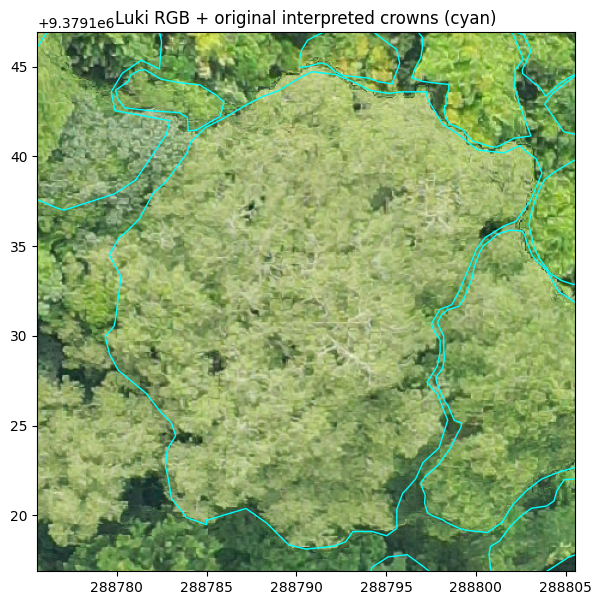

In [10]:
from shapely.strtree import STRtree
from rasterio.windows import from_bounds, bounds as window_bounds
luki=DATA["Luki"]["reference"]
geoms=list(luki.geometry)
parent=list(range(len(geoms)))
def find(i):
    while parent[i]!=i:
        parent[i]=parent[parent[i]];i=parent[i]
    return i
def join(i,j):
    a,b=find(i),find(j)
    if a!=b:parent[max(a,b)]=min(a,b)
tree=STRtree(geoms)
for i,g in enumerate(geoms):
    for j in tree.query(g.buffer(10)):
        j=int(j)
        if j>i and g.distance(geoms[j])<=10+1e-7:join(i,j)
groups={}
for i in range(len(geoms)):groups.setdefault(find(i),[]).append(i)
luki_groups=[]
for k,ids in enumerate(sorted(groups.values(),key=lambda x:-len(x)),1):
    geom=unary_union([geoms[j].buffer(5) for j in ids])
    luki_groups.append({"group_id":f"LUKI_{k:03d}",
                        "n_crowns":len(ids),"geometry":geom})
GROUPS_LUKI=gpd.GeoDataFrame(luki_groups,geometry="geometry",crs=luki.crs)
display(pd.DataFrame({"groups":[len(GROUPS_LUKI)],
                      "crowns":[len(luki)],"max_group":[GROUPS_LUKI.n_crowns.max()]}))
GROUPS_LUKI.to_file(OUT/"09_Luki_annotation_groups.gpkg",driver="GPKG")
# Correct geospatial extent order in imshow: (left, right, bottom, top)
with rasterio.open(SITES["Luki"]["rgb"]) as src:
    c=geoms[0].centroid;x,y=c.x,c.y
    w=from_bounds(x-15,y-15,x+15,y+15,src.transform).round_offsets().round_lengths()
    a=src.read([1,2,3],window=w)
    assert a.size and a.shape[1]>0 and a.shape[2]>0, "Empty Luki RGB window"
    left,bottom,right,top=window_bounds(w,src.transform)
fig,ax=plt.subplots(figsize=(7,7))
ax.imshow(np.moveaxis(a,0,-1),extent=(left,right,bottom,top),origin="upper")
for g in geoms:
    if g.intersects(box(left,bottom,right,top)):
        zz=[g] if g.geom_type=="Polygon" else list(g.geoms)
        for p in zz:
            xx,yy=p.exterior.xy;ax.plot(xx,yy,color="cyan",lw=1)
ax.set_xlim(left,right);ax.set_ylim(bottom,top);ax.set_aspect("equal")
ax.set_title("Luki RGB + original interpreted crowns (cyan)")
display(fig);plt.close(fig)


## 10 — Scientific synthesis and current status

Read-only baseline, reference QA, historical cache validation and a **targeted ecological SAM3 pilot plan**. This notebook does not yet contain an executable new GPU model adapter or trained SAM3 weights. Any claim of improvement requires plot/group-held-out ecological evaluation; optimistic proposal oracle recall alone is insufficient.


In [11]:
status={
  "notebook":"KVO_06_v2_SAM3_ecological_stand_analysis",
  "sites":["Baego","Luki"],
  "reference_policy":{
    "Baego_Kristof":"exhaustive coarse crowns in six ROIs",
    "Baego_Nadine":"precise sparse crown boundaries",
    "Luki":"exhaustive photointerpretation, evaluation edges to audit"},
  "research_priority":"stand ecological performance of raw/processed/adapted SAM3",
  "Musanga_interpretation":"predicted succession proxy, not observed age",
  "SAM1":"historical comparator only","SAM2":"not planned",
  "GPU_inference_enabled":bool(RUN_GPU_INFERENCE)
}
print(json.dumps(status,indent=2))


{
  "notebook": "KVO_06_v2_SAM3_ecological_stand_analysis",
  "sites": [
    "Baego",
    "Luki"
  ],
  "reference_policy": {
    "Baego_Kristof": "exhaustive coarse crowns in six ROIs",
    "Baego_Nadine": "precise sparse crown boundaries",
    "Luki": "exhaustive photointerpretation, evaluation edges to audit"
  },
  "research_priority": "stand ecological performance of raw/processed/adapted SAM3",
  "Musanga_interpretation": "predicted succession proxy, not observed age",
  "SAM1": "historical comparator only",
  "SAM2": "not planned",
  "GPU_inference_enabled": false
}


## 11 — Canonical three-reference population audit

Kristof provides the coarse but exhaustive Baego crown inventory. Nadine provides geometrically detailed but **non-exhaustive** Baego crowns. Luki provides exhaustive interpreted crowns. Do not conflate reference boundary quality with inventory completeness or assume that a buffered crown group is a physically measured plot.


In [12]:
# SECTION 11 — Population audit; run after Sections 0,1,2,9.
assert all(k in globals() for k in ("DATA","GROUPS_LUKI","OUT"))
K=DATA["Baego"]["reference"]
N=DATA["Baego"]["nadine"]
R=DATA["Baego"]["rois"]
L=DATA["Luki"]["reference"]
def fully_within11(frame,polygons):
    return np.array([sum(q.covers(g) for q in polygons)
                     for g in frame.geometry],dtype=int)
ki=fully_within11(K,R.geometry)
ni=fully_within11(N,R.geometry)
li=fully_within11(L,GROUPS_LUKI.geometry)
reference_audit11=pd.DataFrame([
    dict(site="Baego",reference="Kristof exhaustive",all_crowns=len(K),
        inside_groups=int((ki>0).sum()),outside_groups=int((ki==0).sum()),
        multiple_groups=int((ki>1).sum()),usage="stand F1, count, canopy"),
    dict(site="Baego",reference="Nadine detailed sparse",all_crowns=len(N),
        inside_groups=int((ni>0).sum()),outside_groups=int((ni==0).sum()),
        multiple_groups=int((ni>1).sum()),usage="conditional boundary quality"),
    dict(site="Luki",reference="Exhaustive photointerpretation",all_crowns=len(L),
        inside_groups=int((li>0).sum()),outside_groups=int((li==0).sum()),
        multiple_groups=int((li>1).sum()),usage="stand F1 after boundary audit")
])
display(reference_audit11)
reference_audit11.to_csv(OUT/"11_reference_population.csv",index=False)
assert int((li>0).sum())==len(L), "Luki crown lost in derived-group geometry"
assert (ki>0).sum()>0 and (ni>0).sum()>0
print("Section 11 passed: three reference populations explicitly separated.")
print("Historical Baego six-ROI population: 1,107 Kristof / 224 Nadine;")
print("verify the freshly calculated inside_groups against these historical values.")


,site,reference,all_crowns,inside_groups,outside_groups,multiple_groups,usage
0,Baego,Kristof exhaustive,1175,1107,68,0,"stand F1, count, canopy"
1,Baego,Nadine detailed sparse,314,224,90,0,conditional boundary quality
2,Luki,Exhaustive photointerpretation,1856,1856,0,0,stand F1 after boundary audit


Section 11 passed: three reference populations explicitly separated.
Historical Baego six-ROI population: 1,107 Kristof / 224 Nadine;
verify the freshly calculated inside_groups against these historical values.


In [13]:
# SECTION 12 — Scientific prioritization. Supersedes previous full 3-model GPU worklist.
SCIENCE12={
  "primary_model":"SAM3",
  "historical_control":"SAM1_ViTH cached Baego only",
  "not_planned":"full SAM2 or SAM1 inference on Luki",
  "sites":["Baego","Luki"],
  "reference_roles":{
    "Baego_Kristof":"exhaustive but coarse crowns in six plots; stand ecological metrics",
    "Baego_Nadine":"precise, non-exhaustive boundaries; conditional geometric quality",
    "Luki":"exhaustive crowns; spatial footprint and edge sensitivity required"},
  "treatments":["raw_SAM3","processed_SAM3","adapted_selection_or_SAM3_if_supported"],
  "stand_metrics":["crown_count_density_ha","sum_CPA_m2_ha",
                   "union_canopy_cover","crown_size_distribution",
                   "count_CPA_cover_bias","precision_recall_F1"],
  "covariate":"Musanga CNN-derived probability-weighted canopy fraction; successional indicator, not chronological age",
  "pilot":"12 stratified Luki cores, 20m output, 40/80m context, 24 SAM3 jobs maximum",
  "full_site_inference":"deferred_pending_pilot",
  "splitting":"hold out whole Luki groups or whole Baego ROIs; never split overlapping neighboring cores"
}
display(pd.DataFrame([{"field":k,"value":str(v)} for k,v in SCIENCE12.items()]))
(OUT/"12_scientific_priority.json").write_text(json.dumps(SCIENCE12,indent=2))
print("SAM3 ecological science plan active; SAM1/SAM2 full-grid GPU inference cancelled.")


,field,value
0,primary_model,SAM3
1,historical_control,SAM1_ViTH cached Baego only
2,not_planned,full SAM2 or SAM1 inference on Luki
3,sites,"['Baego', 'Luki']"
4,reference_roles,{'Baego_Kristof': 'exhaustive but coarse crown...
5,treatments,"['raw_SAM3', 'processed_SAM3', 'adapted_select..."
6,stand_metrics,"['crown_count_density_ha', 'sum_CPA_m2_ha', 'u..."
7,covariate,Musanga CNN-derived probability-weighted canop...
8,pilot,"12 stratified Luki cores, 20m output, 40/80m c..."
9,full_site_inference,deferred_pending_pilot


SAM3 ecological science plan active; SAM1/SAM2 full-grid GPU inference cancelled.


## 13 — Verified historical Baego SAM cache audit (CPU)

The historical SAM1 ViT-H and SAM3_permissive six-ROI prediction GeoJSONs are reusable. This validates cache **completeness**, not ecological accuracy. Section 13 supersedes the erroneous cache-path check in the original Section 12.


In [14]:
# SECTION 13 — Authoritative cached-prediction verification; CPU only.
import json, hashlib
from shapely.geometry import shape, box
assert "DATA" in globals() and "OLD" in globals() and "OUT" in globals()
D58_13=OLD/"experiments_v58b_luki_context_sam1_sam3"
CANONICAL_13={"SAM1_ViTH":"SAM1_ViTH","SAM3":"SAM3_permissive"}
ROI_13=DATA["Baego"]["rois"]
CORE_M_13=40.0
rows13=[]
by_file13=[]
for rid,region in enumerate(ROI_13.geometry):
    x0,y0,x1,y1=region.bounds
    squares=[box(x,y,x+CORE_M_13,y+CORE_M_13)
        for x in np.arange(x0,x1,CORE_M_13)
        for y in np.arange(y0,y1,CORE_M_13)
        if box(x,y,x+CORE_M_13,y+CORE_M_13).intersects(region)]
    for model,dirname in CANONICAL_13.items():
        folder=D58_13/dirname/f"roi{rid}"
        missing=0;invalid=0;seen=0;features=0;first_bad=[]
        for idx,core in enumerate(squares):
            p=folder/f"core_{idx:03d}.geojson"
            if not p.exists():
                missing+=1
                if len(first_bad)<3:first_bad.append(str(p))
                continue
            seen+=1
            try:
                obj=json.loads(p.read_text())
                assert obj.get("type")=="FeatureCollection" and isinstance(obj.get("features"),list)
                count=len(obj["features"])
                for feat in obj["features"]:
                    g=shape(feat["geometry"])
                    assert not g.is_empty and g.is_valid and g.area>0
                features+=count
                by_file13.append(dict(roi=rid,model=model,core_id=idx,
                    file=str(p),features=count,status="valid"))
            except Exception as exc:
                invalid+=1
                if len(first_bad)<3:first_bad.append(f"{p}: {type(exc).__name__}: {exc}")
                by_file13.append(dict(roi=rid,model=model,core_id=idx,
                    file=str(p),features=np.nan,status="invalid"))
        rows13.append(dict(site="Baego",roi=rid,model=model,
            model_cache_label=dirname,expected_core_files=len(squares),
            existing_files=seen,missing_files=missing,invalid_files=invalid,
            polygon_features=features,
            fully_valid=(missing==0 and invalid==0 and len(squares)>0),
            first_problems="; ".join(first_bad)))
CACHE_AUDIT13=pd.DataFrame(rows13)
display(CACHE_AUDIT13.drop(columns="first_problems"))
summary13=CACHE_AUDIT13.groupby("model",as_index=False).agg(
    expected_core_files=("expected_core_files","sum"),
    existing_files=("existing_files","sum"),
    missing_files=("missing_files","sum"),
    invalid_files=("invalid_files","sum"),
    polygon_features=("polygon_features","sum"),
    complete_ROIs=("fully_valid","sum"))
summary13["complete_all_six"]=(summary13.complete_ROIs==6)
display(summary13)
CACHE_AUDIT13.to_csv(OUT/"13_historic_cache_roi_audit.csv",index=False)
summary13.to_csv(OUT/"13_historic_cache_summary.csv",index=False)
pd.DataFrame(by_file13).to_csv(OUT/"13_historic_cache_file_manifest.csv",index=False)
for row in CACHE_AUDIT13.itertuples():
    if not row.fully_valid:print(f"INCOMPLETE {row.model} ROI{row.roi}: {row.first_problems}")

D70_13=OLD/"experiments_v70_autonomous_sam3_multiscale"/"raw_masks_geojson"
pilot_rows13=[]
for row in CORES.itertuples() if CORES is not None else []:
    for context in (40,80,160):
        p=D70_13/f"roi{int(row.roi)}_core{int(row.core_id):02d}_context{context}.geojson"
        pilot_rows13.append(dict(roi=int(row.roi),core=int(row.core_id),
            context_m=context,present=p.exists(),file=str(p)))
PILOT13=pd.DataFrame(pilot_rows13)
if not PILOT13.empty:
    display(PILOT13.groupby("context_m",as_index=False).agg(
        cached=("present","sum"),expected=("present","size")))
    PILOT13.to_csv(OUT/"13_multiscale_24core_cache_audit.csv",index=False)
print("Cache audit finished. Do not relabel old predictions as SAM2.")


,site,roi,model,model_cache_label,expected_core_files,existing_files,missing_files,invalid_files,polygon_features,fully_valid
0,Baego,0,SAM1_ViTH,SAM1_ViTH,17,17,0,0,160,True
1,Baego,0,SAM3,SAM3_permissive,17,17,0,0,209,True
2,Baego,1,SAM1_ViTH,SAM1_ViTH,16,16,0,0,142,True
3,Baego,1,SAM3,SAM3_permissive,16,16,0,0,212,True
4,Baego,2,SAM1_ViTH,SAM1_ViTH,16,16,0,0,204,True
5,Baego,2,SAM3,SAM3_permissive,16,16,0,0,270,True
6,Baego,3,SAM1_ViTH,SAM1_ViTH,16,16,0,0,223,True
7,Baego,3,SAM3,SAM3_permissive,16,16,0,0,270,True
8,Baego,4,SAM1_ViTH,SAM1_ViTH,23,23,0,0,157,True
9,Baego,4,SAM3,SAM3_permissive,23,23,0,0,198,True


,model,expected_core_files,existing_files,missing_files,invalid_files,polygon_features,complete_ROIs,complete_all_six
0,SAM1_ViTH,106,106,0,0,1080,6,True
1,SAM3,106,106,0,0,1430,6,True


,context_m,cached,expected
0,40,24,24
1,80,24,24
2,160,24,24


Cache audit finished. Do not relabel old predictions as SAM2.


In [15]:
# SECTION 14 — Replace the outdated 1,126-GPU-job manifest with a no-inference decision.
# Historical 14_two_site_sam_job_manifest.csv may still exist on Drive for provenance,
# but it is explicitly deprecated; DO NOT schedule those jobs.
assert "CACHE_AUDIT13" in globals(),"Run Section 13 first"
assert CACHE_AUDIT13.query("model=='SAM3'").fully_valid.all(), (
    "Historic Baego SAM3 cache incomplete; inspect Section 13.")
NEW_PLAN14=pd.DataFrame([
    {"priority":1,"site":"Baego","model":"SAM3","scope":"106 cached 40m cores",
     "task":"postprocessing and stand ecological metrics","GPU_jobs":0},
    {"priority":2,"site":"Luki","model":"SAM3","scope":"12 stratified 20m cores x 2 contexts",
     "task":"small autonomous pilot; independent ecological validation","GPU_jobs":24},
    {"priority":3,"site":"Baego","model":"SAM1","scope":"106 cached 40m cores",
     "task":"frozen historical comparator only","GPU_jobs":0},
    {"priority":4,"site":"Baego/Luki","model":"adapted SAM3 or selector",
     "scope":"only after stage-2 diagnosis","task":"test held-out gain in ecological metrics","GPU_jobs":0},
])
display(NEW_PLAN14)
NEW_PLAN14.to_csv(OUT/"14_REVISED_SAM3_priority_plan.csv",index=False)
(OUT/"14_OBSOLETE_manifest_notice.txt").write_text(
    "The old 14_two_site_sam_job_manifest.csv proposed 1126 GPU runs and is deprecated. "
    "Do not execute it. Use 14_REVISED_SAM3_priority_plan.csv and Section 15.\n")
print("PASS: full-site SAM1/SAM2 worklist CANCELLED. 24-job SAM3 pilot is only proposed.")


,priority,site,model,scope,task,GPU_jobs
0,1,Baego,SAM3,106 cached 40m cores,postprocessing and stand ecological metrics,0
1,2,Luki,SAM3,12 stratified 20m cores x 2 contexts,small autonomous pilot; independent ecological...,24
2,3,Baego,SAM1,106 cached 40m cores,frozen historical comparator only,0
3,4,Baego/Luki,adapted SAM3 or selector,only after stage-2 diagnosis,test held-out gain in ecological metrics,0


PASS: full-site SAM1/SAM2 worklist CANCELLED. 24-job SAM3 pilot is only proposed.


## 14B — Baego six-plot zero-shot baseline: original SAM1 vs SAM3 (Luki-style)

**This is the mandatory starting point before the Luki SAM3 pilot in Section 15. CPU-only; no new SAM calls.**

Read the **original NB06 Block60** all-six-ROI ecological measurements, generated directly from the original Block58/59 SAM1 ViT-H and SAM3_permissive automatic-mask GeoJSONs (40 m processing cores, 160 m RGB context, 60 m contextual buffer). Keep the unprocessed *raw* model outputs; no Musanga guidance, reference-derived prompts or learned crown selection. These historical parameters are identified as **Luki-style implementation** after the historical SAM benchmark—not a claim that these models were fitted at Luki.

**Reference roles**: Kristof (1,107 exhaustive, coarser) is the stand-level reference; Nadine (224 detailed but non-exhaustive within the six ROIs) contributes conditional boundary metrics, **never** false-positive precision/F1. Report each Baego ROI separately and pooled totals. Use the frozen Block64 `raw` results as an independent reproduction check for object F1 and canopy spatial IoU, and as the source of the existing *Musanga* percent-cover covariate.

**Important metric distinctions:** summed crown projected area (CPA) **counts overlapping crown polygons multiple times**; canopy cover is the union of crown polygons inside each ROI, divided by plot area. Crown IoU is a matched-object measurement; **canopy spatial IoU** compares whole mapped canopy footprints. Model crown totals include candidates from historically saved tiling; they are not independent field-counted stems. Crown density is a proxy, not a stem inventory.

**Outputs:** one per-plot measured-vs-SAM table, one per-plot skill/bias table, pooled cross-plot summary, Nadine conditional geometry diagnostics and concise figures. Old saved results are never overwritten.

A. BAEGO ORIGINAL REFERENCE vs SAM PREDICTIONS — per ROI, IoU threshold=0.50


,roi,model,reference_area_ha,musanga_cover_pct,ref_count,sam_count,ref_density_ha,sam_density_ha,ref_mean_cpa_m2,sam_mean_cpa_m2,ref_median_cpa_m2,sam_median_cpa_m2,ref_sum_cpa_m2,sam_sum_cpa_m2,ref_sum_cpa_m2_ha,sam_sum_cpa_m2_ha,ref_cover_pct,sam_cover_pct
0,0,SAM1,1.82,12.41,174,160,95.38,87.71,61.84,121.14,32.45,53.96,10760.03,19381.61,5898.48,10624.69,58.82,65.39
1,0,SAM3,1.82,12.41,174,209,95.38,114.57,61.84,105.16,32.45,49.70,10760.03,21978.74,5898.48,12048.40,58.82,78.81
2,1,SAM1,1.77,31.75,146,142,82.68,80.41,65.97,100.87,39.28,55.04,9631.40,14323.16,5454.27,8111.22,54.48,62.14
3,1,SAM3,1.77,31.75,146,212,82.68,120.06,65.97,86.15,39.28,41.51,9631.40,18264.02,5454.27,10342.93,54.48,70.22
4,2,SAM1,1.96,53.09,201,204,102.55,104.08,53.35,78.05,36.98,47.78,10722.57,15921.21,5470.80,8123.21,54.65,59.79
5,2,SAM3,1.96,53.09,201,270,102.55,137.76,53.35,68.24,36.98,44.87,10722.57,18425.04,5470.80,9400.70,54.65,66.61
6,3,SAM1,1.80,44.56,215,223,119.59,124.04,49.02,95.08,30.51,61.07,10539.52,21202.39,5862.37,11793.36,58.56,75.55
7,3,SAM3,1.80,44.56,215,270,119.59,150.18,49.02,75.48,30.51,46.04,10539.52,20380.39,5862.37,11336.14,58.56,78.31
8,4,SAM1,2.16,91.82,198,157,91.66,72.68,59.20,125.09,37.41,55.87,11721.33,19639.03,5426.42,9091.93,54.21,53.76
9,4,SAM3,2.16,91.82,198,198,91.66,91.66,59.20,102.57,37.41,44.14,11721.33,20309.74,5426.42,9402.44,54.21,60.99


B. OBJECT AND ECOLOGICAL QUALITY — per ROI, IoU threshold=0.50


,roi,model,musanga_cover_pct,reference_crowns,predicted_crowns,matched_crowns,precision,recall,f1,median_matched_iou,canopy_spatial_iou,count_bias_pct,sum_cpa_bias_pct,canopy_cover_error_pp,median_matched_area_ratio,matched_cpa_mae_m2,median_matched_centroid_error_m
0,0,SAM1,12.410,174,160,82,0.512,0.471,0.491,0.741,0.588,-8.046,80.126,6.568,1.123,12.928,0.474
1,0,SAM3,12.410,174,209,90,0.431,0.517,0.470,0.733,0.625,20.115,104.263,19.983,1.124,13.389,0.533
2,1,SAM1,31.755,146,142,71,0.500,0.486,0.493,0.738,0.568,-2.740,48.713,7.661,1.119,16.284,0.589
3,1,SAM3,31.755,146,212,89,0.420,0.610,0.497,0.720,0.610,45.205,89.630,15.742,1.111,14.324,0.689
4,2,SAM1,53.090,201,204,101,0.495,0.502,0.499,0.786,0.618,1.493,48.483,5.147,1.085,11.488,0.472
5,2,SAM3,53.090,201,270,120,0.444,0.597,0.510,0.744,0.616,34.328,71.834,11.963,1.064,10.439,0.527
6,3,SAM1,44.564,215,223,115,0.516,0.535,0.525,0.748,0.654,3.721,101.170,16.993,1.183,14.435,0.440
7,3,SAM3,44.564,215,270,123,0.456,0.572,0.507,0.738,0.640,25.581,93.371,19.755,1.158,11.977,0.433
8,4,SAM1,91.818,198,157,70,0.446,0.354,0.394,0.766,0.447,-20.707,67.549,-0.452,1.141,13.727,0.477
9,4,SAM3,91.818,198,198,82,0.414,0.414,0.414,0.763,0.454,0.000,73.272,6.781,1.118,12.596,0.431


C. SIX-PLOT POOLED AND MACRO SUMMARY


,model,n_plots,plot_area_ha,reference_crowns,sam_crowns,matched_crowns,reference_crowns_ha,sam_crowns_ha,reference_CPA_m2_ha,sam_CPA_m2_ha,...,pooled_recall,pooled_F1,mean_plot_F1,mean_plot_matched_crown_IoU,mean_plot_canopy_spatial_IoU,mean_abs_plot_count_bias_pct,mean_abs_plot_CPA_bias_pct,mean_abs_plot_cover_error_pp,area_weighted_reference_cover_pct,area_weighted_sam_cover_pct
0,SAM1,6,11.644,1107,1080,545,95.072,92.753,5814.621,9705.653,...,0.492,0.498,0.497,0.753,0.593,8.141,67.227,6.75,58.065,64.337
1,SAM3,6,11.644,1107,1430,622,95.072,122.812,5814.621,10788.616,...,0.562,0.490,0.488,0.740,0.608,30.313,85.941,13.89,58.065,71.577


D. NADINE PRECISE BUT NON-EXHAUSTIVE REFERENCE — conditional geometry ONLY


,roi,model,iou_threshold,annotated_crowns,recovered,annotated_crown_recall,median_iou_recovered,median_pred_to_nadine_area_ratio
1,0,SAM1,0.5,26,18,0.692,0.863,1.051
4,0,SAM3,0.5,26,22,0.846,0.833,1.018
7,1,SAM1,0.5,28,16,0.571,0.847,1.008
10,1,SAM3,0.5,28,16,0.571,0.812,1.005
13,2,SAM1,0.5,42,28,0.667,0.885,1.007
16,2,SAM3,0.5,42,30,0.714,0.851,0.996
19,3,SAM1,0.5,51,35,0.686,0.857,1.078
22,3,SAM3,0.5,51,36,0.706,0.836,1.075
25,4,SAM1,0.5,39,32,0.821,0.858,0.980
28,4,SAM3,0.5,39,32,0.821,0.824,0.995


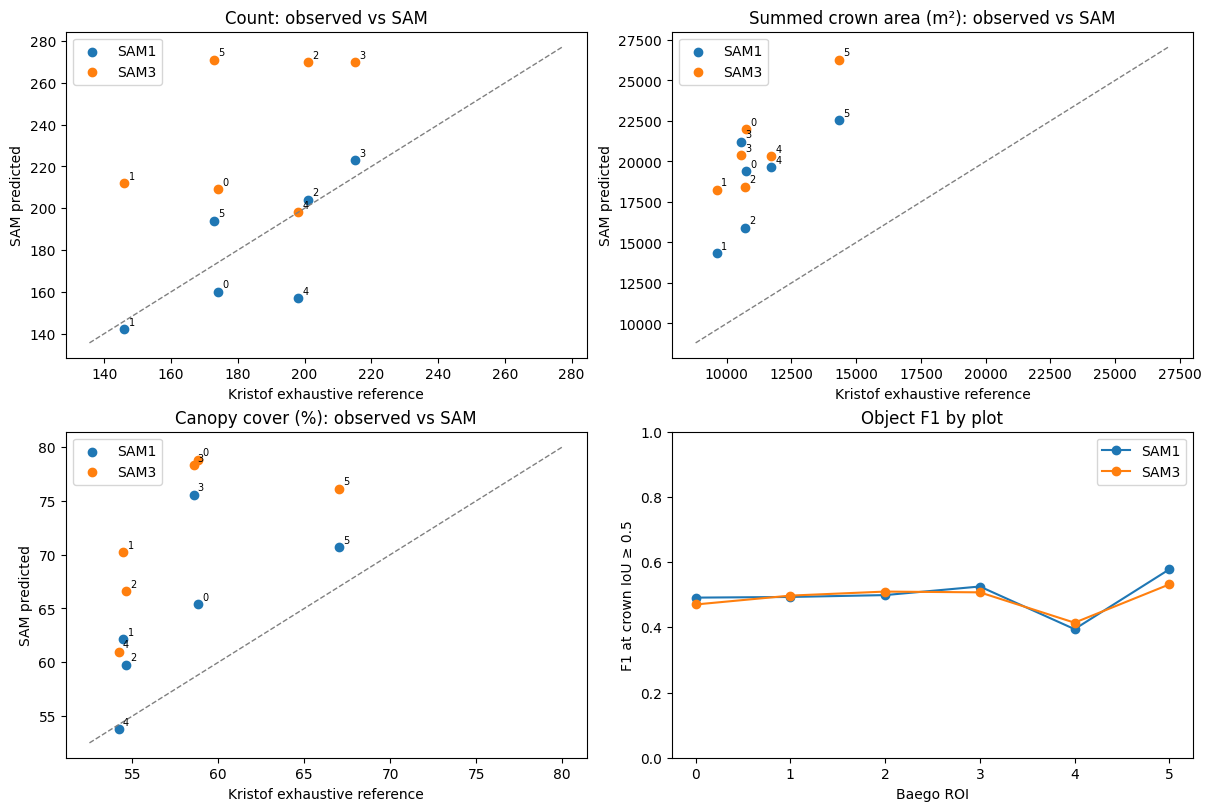

PASS — Historical raw baseline reproduced for both models, six ROIs.
Outputs: /content/drive/MyDrive/Colab Notebooks/Musanga/KVO_work/KVO_06_v2_Baego_Luki/14B_Baego_zero_shot_ecological_baseline


In [16]:
# SECTION 14B — Baego SAM1 vs SAM3 ORIGINAL ZERO-SHOT; CPU and cached CSV only.
# Requirements: Section 0 project setup. Section 13 cache audit recommended.
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
D60B=OLD/"experiments_v60_ecological_validation_all6"
D64B=OLD/"experiments_v64_sixfold_musanga_gradient"
out14b=OUT/"14B_Baego_zero_shot_ecological_baseline"
out14b.mkdir(parents=True,exist_ok=True)
f60=D60B/"all6_ecological_stand_metrics.csv"
f64=D64B/"all6_frozen_metrics.csv"
fnad=D60B/"all6_nadine_sparse_recall.csv"
for f in (f60,f64,fnad):
    assert f.exists(),f"Required original NB06 result missing: {f}"
raw60=pd.read_csv(f60)
raw64=pd.read_csv(f64)
nad60=pd.read_csv(fnad)
M14B={"SAM1_ViTH":"SAM1","SAM3_permissive":"SAM3"}
raw60=raw60[raw60.model.isin(M14B)&np.isclose(raw60.iou_threshold,.5)].copy()
base64=raw64[(raw64.model.isin(M14B))&
              (raw64.method=="raw")&np.isclose(raw64.iou_threshold,.5)].copy()
assert len(raw60)==len(base64)==12,(
    "Expected 6 ROIs x 2 models, at IoU=.5",len(raw60),len(base64))
assert not raw60.duplicated(["roi","model"]).any()
assert not base64.duplicated(["roi","model"]).any()
# Block64 raw is an independently reproduced diagnostic, not a new selected method.
check14b=raw60[["roi","model","f1","precision","recall"]].merge(
    base64[["roi","model","f1","precision","recall"]],
    on=["roi","model"],suffixes=("_60","_64"),validate="one_to_one")
for met in ("f1","precision","recall"):
    assert np.allclose(check14b[f"{met}_60"],check14b[f"{met}_64"],
        atol=1e-8,rtol=1e-7,equal_nan=True),(
        f"Historical raw metric inconsistency: {met}",check14b)
assert raw60.roi.nunique()==6

# Extract a physically interpretable two-model / reference stand table.
# All area metrics are those of original NB06, not silently recomputed.
p=raw60.copy()
p["model"]=p.model.map(M14B)
p["reference_area_ha"]=p.roi_area_ha
p["ref_density_ha"]=p.crown_density_ref_ha
p["sam_density_ha"]=p.crown_density_pred_ha
p["ref_count"]=p.reference_crowns.astype(int)
p["sam_count"]=p.predicted_crowns.astype(int)
p["ref_mean_cpa_m2"]=p.mean_cpa_ref_m2
p["sam_mean_cpa_m2"]=p.mean_cpa_pred_m2
p["ref_median_cpa_m2"]=p.median_cpa_ref_m2
p["sam_median_cpa_m2"]=p.median_cpa_pred_m2
p["ref_sum_cpa_m2"]=p.sum_cpa_ref_m2
p["sam_sum_cpa_m2"]=p.sum_cpa_pred_m2
p["ref_sum_cpa_m2_ha"]=p.sum_cpa_ref_m2/p.roi_area_ha
p["sam_sum_cpa_m2_ha"]=p.sum_cpa_pred_m2/p.roi_area_ha
p["ref_cover_pct"]=p.canopy_cover_ref_pct
p["sam_cover_pct"]=p.canopy_cover_pred_pct
p["cover_error_pp"]=p.canopy_cover_error_pp
p["matched_crowns"]=p.matched.astype(int)
# Spatial canopy IoU and Musanga fraction from the exact same raw candidates.
p=p.merge(base64[["roi","model","canopy_spatial_iou",
                    "musanga_cover_pct"]].assign(
    model=lambda x:x.model.map(M14B)),
    on=["roi","model"],validate="one_to_one")
p=p.sort_values(["roi","model"]).reset_index(drop=True)

columns_measured14b=[
    "roi","model","reference_area_ha","musanga_cover_pct",
    "ref_count","sam_count","ref_density_ha","sam_density_ha",
    "ref_mean_cpa_m2","sam_mean_cpa_m2",
    "ref_median_cpa_m2","sam_median_cpa_m2",
    "ref_sum_cpa_m2","sam_sum_cpa_m2",
    "ref_sum_cpa_m2_ha","sam_sum_cpa_m2_ha",
    "ref_cover_pct","sam_cover_pct"]
MEASURED14B=p[columns_measured14b].copy()
MEASURED14B.to_csv(out14b/"Baego_SAM1_SAM3_plot_measured_vs_predicted.csv",index=False)

columns_skill14b=["roi","model","musanga_cover_pct",
    "reference_crowns","predicted_crowns","matched_crowns",
    "precision","recall","f1","median_matched_iou",
    "canopy_spatial_iou","count_bias_pct","sum_cpa_bias_pct",
    "canopy_cover_error_pp","median_matched_area_ratio",
    "matched_cpa_mae_m2","median_matched_centroid_error_m"]
SKILL14B=p[columns_skill14b].copy()
SKILL14B.to_csv(out14b/"Baego_SAM1_SAM3_plot_detection_ecological_error.csv",index=False)

print("A. BAEGO ORIGINAL REFERENCE vs SAM PREDICTIONS — per ROI, IoU threshold=0.50")
display(MEASURED14B.round(2))
print("B. OBJECT AND ECOLOGICAL QUALITY — per ROI, IoU threshold=0.50")
display(SKILL14B.round(3))

# Pooled counts and areas represent six plots together, while quality has
# both pooled object scores and equally weighted plot-level means.
pooled14b=[]
for model,g in p.groupby("model",sort=True):
    n_ref=int(g.ref_count.sum());n_pred=int(g.sam_count.sum())
    tp=int(g.matched_crowns.sum())
    area=float(g.reference_area_ha.sum())
    ref_cpa=float(g.ref_sum_cpa_m2.sum())
    pred_cpa=float(g.sam_sum_cpa_m2.sum())
    pooled14b.append(dict(model=model,n_plots=len(g),plot_area_ha=area,
        reference_crowns=n_ref,sam_crowns=n_pred,matched_crowns=tp,
        reference_crowns_ha=n_ref/area,sam_crowns_ha=n_pred/area,
        reference_CPA_m2_ha=ref_cpa/area,sam_CPA_m2_ha=pred_cpa/area,
        count_bias_pct=100*(n_pred-n_ref)/n_ref,
        CPA_bias_pct=100*(pred_cpa-ref_cpa)/ref_cpa,
        pooled_precision=tp/n_pred if n_pred else np.nan,
        pooled_recall=tp/n_ref if n_ref else np.nan,
        pooled_F1=2*tp/(n_ref+n_pred),
        mean_plot_F1=float(g.f1.mean()),
        mean_plot_matched_crown_IoU=float(g.median_matched_iou.mean()),
        mean_plot_canopy_spatial_IoU=float(g.canopy_spatial_iou.mean()),
        mean_abs_plot_count_bias_pct=float(g.count_bias_pct.abs().mean()),
        mean_abs_plot_CPA_bias_pct=float(g.sum_cpa_bias_pct.abs().mean()),
        mean_abs_plot_cover_error_pp=float(g.cover_error_pp.abs().mean()),
        area_weighted_reference_cover_pct=float(
            np.average(g.ref_cover_pct,weights=g.reference_area_ha)),
        area_weighted_sam_cover_pct=float(
            np.average(g.sam_cover_pct,weights=g.reference_area_ha))))
POOLED14B=pd.DataFrame(pooled14b)
POOLED14B.to_csv(out14b/"Baego_SAM1_SAM3_sixplot_pooled_summary.csv",index=False)
print("C. SIX-PLOT POOLED AND MACRO SUMMARY")
display(POOLED14B.round(3))

# Sparse Nadine boundary check, without false-positive labels.
NAD14B=nad60[
    nad60.model.isin(M14B)&np.isclose(nad60.iou_threshold,.5)].copy()
assert len(NAD14B)==12
NAD14B["model"]=NAD14B.model.map(M14B)
NAD14B=NAD14B.sort_values(["roi","model"])
NAD14B.to_csv(out14b/"Baego_Nadine_conditional_boundary_metrics.csv",index=False)
print("D. NADINE PRECISE BUT NON-EXHAUSTIVE REFERENCE — conditional geometry ONLY")
display(NAD14B.round(3))

# Reviewer-friendly figure: paired comparisons across all six plots.
fig,axes=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
panels=[
    ("Count: observed vs SAM","ref_count","sam_count"),
    ("Summed crown area (m²): observed vs SAM","ref_sum_cpa_m2","sam_sum_cpa_m2"),
    ("Canopy cover (%): observed vs SAM","ref_cover_pct","sam_cover_pct"),
    ("Object F1 by plot",None,"f1")]
for ax,(title,xcol,ycol) in zip(axes.flat,panels):
    for model,g in p.groupby("model"):
        if xcol is None:
            ax.plot(g.roi,g[ycol],"o-",label=model)
        else:
            ax.scatter(g[xcol],g[ycol],label=model)
            for r in g.itertuples():
                ax.annotate(str(r.roi),(getattr(r,xcol),getattr(r,ycol)),
                            xytext=(3,3),textcoords="offset points",fontsize=7)
    if xcol is not None:
        data_xy=np.concatenate([p[xcol].to_numpy(),p[ycol].to_numpy()])
        lo,hi=float(np.nanmin(data_xy)),float(np.nanmax(data_xy))
        pad=max((hi-lo)*.05,1e-5)
        ax.plot([lo-pad,hi+pad],[lo-pad,hi+pad],"--",color="gray",lw=1)
        ax.set_xlabel("Kristof exhaustive reference")
        ax.set_ylabel("SAM predicted")
    else:
        ax.set_xlabel("Baego ROI")
        ax.set_ylabel("F1 at crown IoU ≥ 0.5")
        ax.set_xticks(range(6))
        ax.set_ylim(0,1)
    ax.set_title(title)
    ax.legend()
fig.savefig(out14b/"Baego_SAM1_vs_SAM3_zero_shot_ecological_baseline.png",
            dpi=180,bbox_inches="tight")
plt.show()
print("PASS — Historical raw baseline reproduced for both models, six ROIs.")
print("Outputs:",out14b)


## 14C — Baego SAM3 processed versus raw: plot ecological benchmark

**CPU-only, after Section 14B.** Reuse six-plot Block64 frozen `SAM3_permissive` outputs for five treatments: `raw`, `confidence_nms`, `rf_rank_nms`, `hybrid_rank_nms` and `nested_cutoff_rf_nms`. No SAM rerun, GPU inference, fitting or threshold selection.

Report per-plot **Kristof measured versus SAM3 predicted** crown count/density, summed projected crown area (CPA), and canopy cover; calculate precision, recall, F1, median crown IoU, spatial canopy IoU, and signed biases. A six-plot summary distinguishes pooled object statistics from plot-level mean absolute errors. Nadine's 224 precisely delineated but non-exhaustive crowns inform **conditional** recovery and delineation.

**Interpretation:** Learned selection had leave-one-ROI-out fitting/selection in the historical benchmark, but is not a completely independent external-site evaluation. Reference stand values for each processing method are identical; absolute predicted CPA and cover reconstructed from previously saved reference metrics and biases (not a new vector-geometric calculation). Musanga cover is a putative successional indicator, not measured age.

In [ ]:
# SECTION 14C — Baego processed SAM3 ecology, frozen Block64 results; CPU only.
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
assert "MEASURED14B" in globals() and "SKILL14B" in globals(), "Run Section 14B first"
D64C=OLD/"experiments_v64_sixfold_musanga_gradient"
OUT14C=OUT/"14C_Baego_SAM3_ecological_postprocessing"
OUT14C.mkdir(exist_ok=True,parents=True)
methods14c=["raw","confidence_nms","rf_rank_nms","hybrid_rank_nms","nested_cutoff_rf_nms"]
a=pd.read_csv(D64C/"all6_frozen_metrics.csv")
a=a[(a.model=="SAM3_permissive")&np.isclose(a.iou_threshold,.5)&a.method.isin(methods14c)].copy()
assert len(a)==30 and not a.duplicated(["roi","method"]).any()
# Block64 already contains the authoritative Musanga-cover column.
# Check Section 14B's value, but do not merge that duplicate column.
reference_full=MEASURED14B.query("model == 'SAM3'").copy()
assert len(reference_full)==6
reference=reference_full[["roi","reference_area_ha",
   "ref_count","ref_density_ha","ref_sum_cpa_m2",
   "ref_sum_cpa_m2_ha","ref_cover_pct"]]
a=a.merge(reference,on="roi",validate="many_to_one")
expected_musanga=a.roi.map(reference_full.set_index("roi").musanga_cover_pct)
assert np.allclose(a.musanga_cover_pct,expected_musanga,
                   atol=1e-5,rtol=1e-6), "Block64 vs Section14B Musanga cover mismatch"
assert np.array_equal(a.reference_n.to_numpy(),a.ref_count.to_numpy())
a["sam_count"]=a.pred_n.astype(int)
a["sam_density_ha"]=a.sam_count/a.reference_area_ha
a["sam_sum_cpa_m2"]=a.ref_sum_cpa_m2*(1+a.sum_cpa_bias_pct/100.)
a["sam_sum_cpa_m2_ha"]=a.sam_sum_cpa_m2/a.reference_area_ha
a["sam_cover_pct"]=a.ref_cover_pct+a.canopy_cover_error_pp
a["abs_count_bias_pct"]=a.count_bias_pct.abs()
a["abs_CPA_bias_pct"]=a.sum_cpa_bias_pct.abs()
a["abs_cover_error_pp"]=a.canopy_cover_error_pp.abs()

# Reproduce original unprocessed SAM3 reference from Block14B exactly.
raw=a[a.method=="raw"].sort_values("roi")
base=SKILL14B.query("model == 'SAM3'").sort_values("roi")
assert np.array_equal(raw.sam_count.to_numpy(),base.predicted_crowns.to_numpy())
assert np.allclose(raw.f1.to_numpy(),base.f1.to_numpy(),atol=1e-8)
assert np.allclose(raw.canopy_spatial_iou.to_numpy(),base.canopy_spatial_iou.to_numpy(),atol=1e-8)

fields=["roi","method","musanga_cover_pct","reference_area_ha",
"ref_count","sam_count","ref_density_ha","sam_density_ha",
"ref_sum_cpa_m2","sam_sum_cpa_m2","ref_sum_cpa_m2_ha","sam_sum_cpa_m2_ha",
"ref_cover_pct","sam_cover_pct","matches","precision","recall","f1",
"median_matched_iou","canopy_spatial_iou","count_bias_pct",
"sum_cpa_bias_pct","canopy_cover_error_pp"]
PLOT14C=a[fields].sort_values(["roi","method"]).reset_index(drop=True)
PLOT14C.to_csv(OUT14C/"14C_SAM3_per_plot_reference_vs_predictions.csv",index=False)
print("A. PLOT-LEVEL MEASURED VS SAM3 (5 postprocessing treatments, six plots)")
display(PLOT14C.round(2))

summary=[]
for method,g in a.groupby("method"):
    ref_n=int(g.ref_count.sum());pred_n=int(g.sam_count.sum());tp=int(g.matches.sum())
    ref_cpa=g.ref_sum_cpa_m2.sum();pred_cpa=g.sam_sum_cpa_m2.sum()
    summary.append(dict(method=method,reference_n=ref_n,predicted_n=pred_n,
        matched_n=tp,pooled_precision=tp/pred_n,
        pooled_recall=tp/ref_n,pooled_F1=2*tp/(ref_n+pred_n),
        mean_plot_F1=g.f1.mean(),mean_canopy_spatial_IoU=g.canopy_spatial_iou.mean(),
        pooled_count_bias_pct=100*(pred_n-ref_n)/ref_n,
        mean_abs_plot_count_bias_pct=g.abs_count_bias_pct.mean(),
        pooled_CPA_bias_pct=100*(pred_cpa-ref_cpa)/ref_cpa,
        mean_abs_plot_CPA_bias_pct=g.abs_CPA_bias_pct.mean(),
        mean_abs_cover_error_pp=g.abs_cover_error_pp.mean(),
        area_weighted_predicted_cover_pct=np.average(g.sam_cover_pct,weights=g.reference_area_ha)))
SUMMARY14C=pd.DataFrame(summary).set_index("method").loc[methods14c].reset_index()
SUMMARY14C.to_csv(OUT14C/"14C_SAM3_six_plot_method_summary.csv",index=False)
print("B. COMPARISON ACROSS SIX BAEGO PLOTS")
display(SUMMARY14C.round(3))

raw_by_roi=raw.set_index("roi")
paired=[]
for x in a.itertuples():
    y=raw_by_roi.loc[x.roi]
    paired.append(dict(roi=int(x.roi),method=x.method,
        delta_F1=x.f1-y.f1,
        improvement_abs_count_bias_pct=abs(y.count_bias_pct)-abs(x.count_bias_pct),
        improvement_abs_CPA_bias_pct=abs(y.sum_cpa_bias_pct)-abs(x.sum_cpa_bias_pct),
        improvement_abs_cover_error_pp=abs(y.canopy_cover_error_pp)-abs(x.canopy_cover_error_pp),
        delta_canopy_spatial_IoU=x.canopy_spatial_iou-y.canopy_spatial_iou))
PAIRED14C=pd.DataFrame(paired)
PAIRED14C.to_csv(OUT14C/"14C_per_plot_change_vs_raw.csv",index=False)
print("C. AVERAGE ECOLOGICAL IMPROVEMENT RELATIVE TO RAW SAM3")
display(PAIRED14C.groupby("method",as_index=False).mean(numeric_only=True).round(3))

nd=pd.read_csv(D64C/"nadine_sparse_geometry.csv")
nd=nd[(nd.model=="SAM3_permissive")&np.isclose(nd.iou_threshold,.5)&
      nd.method.isin(methods14c)]
assert len(nd)==30
NAD14C=nd.groupby("method",as_index=False).agg(
    nadine_n=("nadine_n","sum"),recovered_n=("recovered_n","sum"),
    mean_roi_conditional_IoU=("conditional_median_iou","mean"),
    mean_roi_area_ratio=("conditional_median_area_ratio","mean"))
NAD14C["conditional_recall"]=NAD14C.recovered_n/NAD14C.nadine_n
NAD14C.to_csv(OUT14C/"14C_Nadine_conditional_geometry.csv",index=False)
print("D. NADINE PRECISE NON-EXHAUSTIVE CROWN RECOVERY")
display(NAD14C.round(3))

fig,axes=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
metrics=[("Mean plot F1","mean_plot_F1"),
    ("Mean absolute crown count bias (%)","mean_abs_plot_count_bias_pct"),
    ("Mean absolute CPA bias (%)","mean_abs_plot_CPA_bias_pct"),
    ("Mean absolute canopy-cover error (pp)","mean_abs_cover_error_pp")]
for ax,(name,key) in zip(axes.ravel(),metrics):
    ax.bar(range(len(SUMMARY14C)),SUMMARY14C[key])
    ax.set_xticks(range(len(SUMMARY14C)),["Raw","Conf+NMS","RF+NMS","Hybrid+NMS","Nested RF"],
                  rotation=25,ha="right")
    ax.set_title(name)
fig.savefig(OUT14C/"14C_SAM3_ecological_tradeoffs.png",dpi=160,bbox_inches="tight")
plt.show()
print("PASS — cached Baego SAM3 postprocessing evaluation complete, no new inference.")


## 14D — Crown-size distributions: frozen pre-training ecological baseline

**Objective:** freeze crown-size distribution and ecological-structure endpoints before fine-tuning SAM3. Compare the exhaustive Baego Kristof reference to original raw SAM3 and existing confidence+NMS selection, without new inference or fitting. Historical selected candidate IDs must reproduce Section 14C.

Report log-scale ECDFs, P10/P25/P50/P75/P90/P95, 5–10/10–20/20–40/40–80/80–160/160+ m² class proportions by **crown count and projected area**, and distribution-distance errors by plot. Interpretation of changes along the Musanga gradient is exploratory (six plots); independent out-of-plot and Luki evaluation will be needed for adaptation claims.

**Next step is training SAM3, not another hyperparameter search.** Validate RGB/crown-mask tiles, spatial folds, checkpoint trainability and autonomous mask-generation evaluation. Do not mistake improving prompted-mask IoU for improving autonomous crown detection.

In [ ]:
# SECTION 14D — Reference vs raw/processed SAM3 crown-size distributions, CPU.
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance, spearmanr
from shapely.geometry import shape, box
from IPython.display import display
assert "PLOT14C" in globals() and "D58_13" in globals()
OUT14D=OUT/"14D_distribution_baseline";OUT14D.mkdir(exist_ok=True,parents=True)
bins=np.array([5,10,20,40,80,160,np.inf])
labels=["5-10","10-20","20-40","40-80","80-160","160+"]
ids=pd.read_csv(OLD/"experiments_v64_sixfold_musanga_gradient"/"selected_candidate_ids.csv")
ids=ids.query("model == 'SAM3_permissive' and method == 'confidence_nms'")
rows=[];hist=[];errs=[];values={}
for rid,roi in enumerate(DATA["Baego"]["rois"].geometry):
    refs=list(DATA["Baego"]["reference"].loc[
        DATA["Baego"]["reference"].geometry.apply(roi.covers),"geometry"])
    x0,y0,x1,y1=roi.bounds
    cores=[box(x,y,x+40,y+40) for x in np.arange(x0,x1,40)
           for y in np.arange(y0,y1,40) if box(x,y,x+40,y+40).intersects(roi)]
    preds=[]
    for cid,_ in enumerate(cores):
        p=D58_13/"SAM3_permissive"/f"roi{rid}"/f"core_{cid:03d}.geojson"
        assert p.exists(),p
        for feat in json.loads(p.read_text())["features"]:
            g=polygons_only(shape(feat["geometry"]))
            if g is not None and not g.is_empty and g.area>0:preds.append(g)
    selected=ids.loc[ids.roi==rid,"candidate_id"].astype(int).tolist()
    assert len(selected)==len(set(selected)) and all(0<=j<len(preds) for j in selected)
    sets={"Reference":refs,"SAM3 raw":preds,"SAM3 confidence NMS":[preds[j] for j in selected]}
    old=PLOT14C[PLOT14C.roi==rid].set_index("method")
    assert len(refs)==old.loc["raw","ref_count"]
    assert len(preds)==old.loc["raw","sam_count"]
    assert len(selected)==old.loc["confidence_nms","sam_count"]
    for label,polygons in sets.items():
        v=np.array([g.area for g in polygons],dtype=float)
        assert v.size>0 and np.isfinite(v).all() and (v>0).all()
        values[(rid,label)]=v
        q=np.quantile(v,[.1,.25,.5,.75,.9,.95])
        rows.append(dict(roi=rid,method=label,n=len(v),mean_m2=v.mean(),
          CV=float(v.std()/v.mean()),fraction_below5=float(np.mean(v<5)),
          P10=q[0],P25=q[1],P50=q[2],P75=q[3],P90=q[4],P95=q[5],
          max_m2=v.max(),fraction_ge80=float(np.mean(v>=80)),
          CPA_fraction_ge80=float(v[v>=80].sum()/v.sum())))
        counts=np.histogram(v,bins=bins)[0]
        parts=np.array([v[(v>=bins[k])&(v<bins[k+1])].sum() for k in range(6)])
        for k in range(6):
            hist.append(dict(roi=rid,method=label,class_m2=labels[k],count=int(counts[k]),
                  number_share=float(counts[k]/counts.sum()) if counts.sum() else np.nan,
                  area_share=float(parts[k]/parts.sum()) if parts.sum() else np.nan))
    ref=values[(rid,"Reference")]
    for method in ("SAM3 raw","SAM3 confidence NMS"):
        pred=values[(rid,method)]
        a=np.histogram(ref,bins=bins)[0].astype(float)
        b=np.histogram(pred,bins=bins)[0].astype(float)
        a/=a.sum();b/=b.sum()
        errs.append(dict(roi=rid,method=method,
            log_area_wasserstein=wasserstein_distance(np.log1p(ref),np.log1p(pred)),
            histogram_total_variation=float(np.abs(a-b).sum()/2),
            P50_absolute_error_m2=abs(np.median(pred)-np.median(ref)),
            P90_absolute_error_m2=abs(np.quantile(pred,.9)-np.quantile(ref,.9)),
            P95_absolute_error_m2=abs(np.quantile(pred,.95)-np.quantile(ref,.95))))
STATS14D=pd.DataFrame(rows);HIST14D=pd.DataFrame(hist);ERROR14D=pd.DataFrame(errs)
for filename,table in [("quantiles.csv",STATS14D),("class_distributions.csv",HIST14D),
                       ("distribution_errors.csv",ERROR14D)]:
    table.to_csv(OUT14D/filename,index=False)
print("A. Per-plot crown size distribution descriptors");display(STATS14D.round(2))
print("B. Per-plot distribution errors");display(ERROR14D.round(3))
print("C. Equal-plot average distribution error")
display(ERROR14D.groupby("method").mean(numeric_only=True).drop(columns="roi").round(3))
fig,axes=plt.subplots(2,3,figsize=(13,7),sharex=True,sharey=True,constrained_layout=True)
for rid,ax in enumerate(axes.flat):
    for name in ("Reference","SAM3 raw","SAM3 confidence NMS"):
        v=np.sort(values[(rid,name)])
        ax.step(v,np.arange(1,len(v)+1)/len(v),where="post",label=name)
    ax.set_xscale("log");ax.set_title(f"Baego ROI {rid}")
    ax.set_xlabel("Crown projected area (m²)");ax.set_ylabel("ECDF")
axes.flat[0].legend(fontsize=8)
fig.savefig(OUT14D/"Baego_crown_area_ECDFs.png",dpi=160)
plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for ax,col,title in zip(axes,["number_share","area_share"],
                         ["Number-weighted classes","Area-weighted classes"]):
    for name in ("Reference","SAM3 raw","SAM3 confidence NMS"):
        p=HIST14D[HIST14D.method==name].groupby("class_m2")[col].mean().reindex(labels)
        ax.plot(labels,p,marker="o",label=name)
    ax.set_title(title);ax.tick_params(axis="x",rotation=35);ax.legend(fontsize=8)
fig.savefig(OUT14D/"Baego_number_vs_area_distributions.png",dpi=160)
plt.show()
mus=PLOT14C.query("method == 'raw'")[["roi","musanga_cover_pct"]]
ecol=STATS14D[STATS14D.method=="Reference"].merge(mus,on="roi")
print("D. Musanga associations (exploratory, n=6 plots)")
for k in ("P50","P90","P95","CV","fraction_ge80","CPA_fraction_ge80"):
    rho,pv=spearmanr(ecol.musanga_cover_pct,ecol[k])
    print(k,"Spearman rho",round(float(rho),3),"exploratory p",round(float(pv),3))
contract={"next_step":"SAM3 fine-tuning on spatially blocked RGB/crown-mask training data",
 "benchmark":"autonomous predictions on untouched plots, same reference geometries",
 "primary_comparator":"SAM3 confidence NMS",
 "distribution_metrics":["log_area_wasserstein","histogram_total_variation",
                         "P50_absolute_error_m2","P90_absolute_error_m2",
                         "P95_absolute_error_m2","number_share","area_share"],
 "stand_metrics":["count_density_ha","sum_CPA_m2_ha","union_canopy_cover_pct"],
 "guardrails":["crown precision","recall","F1 IoU>=0.5","Nadine conditional boundary IoU"],
 "Musanga":"independent ecological gradient indicator, not stand age"}
(OUT14D/"frozen_training_evaluation_contract.json").write_text(json.dumps(contract,indent=2))
print("PASS — Pre-training distribution baseline frozen. NO SAM training executed.")


## 15 — Luki SAM3-only pilot: select a small, ecologically informative sample (CPU)

**Why not all 1,856 crowns?** SAM3 operates on RGB tiles, not on individually annotated trees. We need representative **stand units** with independent reference counts, crown area and canopy cover. An initial 12-core pilot (20 × 20 m) at 40 m and 80 m RGB contexts means at most **24 new SAM3 inference calls**, not 1,020.

Select the cores **without using SAM outputs**. Candidate cores come from the deterministic 40 m grid in the old Section 14 manifest, but are subdivided into four 20 m squares, and are then filtered by their coverage within the 20 Luki annotated groups. We compute Musanga CNN probability fraction from valid raster pixels, properly decoding uint16 / 10000 (65535 = NoData). This is an **indicator of Musanga abundance**, not a measured forest age. Sampling covers low/medium/high predicted Musanga fractions and multiple spatially independent groups. It is *stratified for method development*, not an unbiased site-wide age response estimate.

First review the selected 12 plot footprints and probability valid-pixel coverage. Sparse probability support and group-boundary uncertainty must be reported; do not infer site-wide precision if reference/image coverage is incomplete.

In [17]:
# SECTION 15 — 12-core Luki ecological pilot; no SAM inference.
from rasterio.windows import from_bounds
from rasterio.features import geometry_mask
from shapely.geometry import box, mapping
assert all(k in globals() for k in ("DATA","SITES","GROUPS_LUKI","OUT"))
CORE15=20.0
CONTEXT15=(40,80)
N_PILOT15=12
luki15=DATA["Luki"]["reference"]
groups15=GROUPS_LUKI
candidates15=[]
for group_idx,g in enumerate(groups15.geometry):
    xmin,ymin,xmax,ymax=g.bounds
    # Deterministic image grid, from geometry alone; no crown positions used.
    for x in np.arange(np.floor(xmin/CORE15)*CORE15,xmax,CORE15):
        for y in np.arange(np.floor(ymin/CORE15)*CORE15,ymax,CORE15):
            core=box(float(x),float(y),float(x+CORE15),float(y+CORE15))
            fraction=float(core.intersection(g).area/core.area)
            if fraction>=0.80:
                candidates15.append(dict(group_id=str(groups15.group_id.iloc[group_idx]),
                    x=float(x),y=float(y),core_m=CORE15,
                    group_coverage=fraction,geometry=core))
assert candidates15,"No suitable Luki pilot cores; inspect ROI buffer footprints"
# A candidate can intersect multiple groups. Retain the best matching group.
candidates15=sorted(candidates15,key=lambda p:(p["x"],p["y"],-p["group_coverage"]))
dedup15={}
for rec in candidates15:dedup15.setdefault((rec["x"],rec["y"]),rec)
candidates15=list(dedup15.values())
probpath15=SITES["Luki"]["probability"]
assert probpath15.exists(),probpath15
with rasterio.open(probpath15) as src:
    assert src.count==1 and src.dtypes[0]=="uint16"
    for rec in candidates15:
        w=from_bounds(rec["x"],rec["y"],rec["x"]+CORE15,
                      rec["y"]+CORE15,src.transform).round_offsets().round_lengths()
        data=src.read(1,window=w,boundless=True,fill_value=65535)
        valid=(data!=65535)&(data<=10000)
        rec["probability_coverage"]=float(valid.mean()) if data.size else 0
        if valid.any():
            v=data[valid].astype(np.float32)/10000.
            rec["musanga_mean_probability"]=float(v.mean())
            rec["musanga_high_prob_fraction"]=float(np.mean(v>=0.5))
        else:
            rec["musanga_mean_probability"]=np.nan
            rec["musanga_high_prob_fraction"]=np.nan
# Crowns completely inside each core: no edge-cut reference counting.
ref_geoms15=list(luki15.geometry)
for rec in candidates15:
    rec["complete_ref_crowns"]=sum(
        box(rec["x"],rec["y"],rec["x"]+CORE15,rec["y"]+CORE15).covers(g)
        for g in ref_geoms15)
CAND15=pd.DataFrame([{k:v for k,v in rec.items() if k!="geometry"}
                      for rec in candidates15])
print("Eligible footprint cores:",len(CAND15))
display(CAND15[["group_coverage","probability_coverage",
                "musanga_mean_probability","complete_ref_crowns"]].describe())
# Require usable CNN support and multiple reference crowns for preliminary evaluation.
usable15=CAND15.query("probability_coverage >= 0.50 and complete_ref_crowns >= 2").copy()
assert len(usable15)>=N_PILOT15, (
    f"Only {len(usable15)} eligible cores; relax pilot eligibility transparently.")
usable15=usable15.sort_values(["musanga_mean_probability","group_id","x","y"])
# Quantile-stratified ordering plus preference for different groups.
usable15["stratum"]=pd.qcut(
    usable15.musanga_mean_probability.rank(method="first"),q=3,
    labels=["low","medium","high"])
selected15=[]
group_use15={}
for stratum,grp in usable15.groupby("stratum",observed=True):
    ranked=grp.sort_values(["group_id","x","y"])
    for rec in ranked.itertuples():
        if sum(x["stratum"]==stratum for x in selected15)>=4:break
        if group_use15.get(rec.group_id,0)>=2:continue
        entry=rec._asdict()
        selected15.append(entry)
        group_use15[rec.group_id]=group_use15.get(rec.group_id,0)+1
assert len(selected15)==N_PILOT15, (
  f"Selected {len(selected15)} rather than {N_PILOT15}; "
  "group diversity constraint too strict for available Luki geometries")
PILOT15=pd.DataFrame(selected15)
PILOT15.insert(0,"pilot_id",np.arange(len(PILOT15),dtype=int))
display(PILOT15[["pilot_id","group_id","stratum","x","y","group_coverage",
                 "probability_coverage","musanga_mean_probability",
                 "musanga_high_prob_fraction","complete_ref_crowns"]])
PILOT15.to_csv(OUT/"15_Luki_SAM3_pilot_core_manifest.csv",index=False)
runs15=[]
for rec in PILOT15.itertuples():
    for context_m in CONTEXT15:
        pad=(context_m-CORE15)/2.
        runs15.append(dict(pilot_id=int(rec.pilot_id),
          group_id=rec.group_id,context_m=context_m,
          core_x=float(rec.x),core_y=float(rec.y),core_m=CORE15,
          xmin=rec.x-pad,ymin=rec.y-pad,xmax=rec.x+CORE15+pad,
          ymax=rec.y+CORE15+pad,
          musanga_mean_probability=float(rec.musanga_mean_probability),
          status="pending_SAM3_GPU",
          target_file=str(OUT/"15_SAM3_pilot_predictions"/
             f"luki_core{int(rec.pilot_id):02d}_context{context_m}.geojson")))
RUNS15=pd.DataFrame(runs15)
RUNS15.to_csv(OUT/"15_Luki_SAM3_pilot_GPU_worklist.csv",index=False)
print("Luki SAM3 pilot:",len(PILOT15),"cores x",len(CONTEXT15),
      "contexts =",len(RUNS15),"planned GPU calls. NO SAM inference executed.")


Eligible footprint cores: 603


,group_coverage,probability_coverage,musanga_mean_probability,complete_ref_crowns
count,603.000000,603.000000,603.000000,603.000000
mean,0.972218,0.972288,0.173852,0.887231
std,0.050414,0.050337,0.154270,1.132671
min,0.801525,0.805671,0.004546,0.000000
25%,0.970548,0.971113,0.056173,0.000000
50%,1.000000,1.000000,0.126793,1.000000
75%,1.000000,1.000000,0.244237,1.000000
max,1.000000,1.000000,0.809495,6.000000


,pilot_id,group_id,stratum,x,y,group_coverage,probability_coverage,musanga_mean_probability,musanga_high_prob_fraction,complete_ref_crowns
0,0,LUKI_001,low,290060.0,9379020.0,1.000000,1.000000,0.015350,0.000134,2
1,1,LUKI_001,low,290080.0,9379040.0,1.000000,1.000000,0.041300,0.027875,2
2,2,LUKI_003,low,290020.0,9379220.0,0.948518,0.948691,0.049015,0.027732,2
3,3,LUKI_003,low,290100.0,9379180.0,1.000000,1.000000,0.039546,0.000123,2
4,4,LUKI_004,medium,289920.0,9378240.0,0.975854,0.976823,0.178301,0.154303,2
5,5,LUKI_004,medium,289940.0,9378260.0,1.000000,1.000000,0.134720,0.058814,2
6,6,LUKI_005,medium,288720.0,9378060.0,1.000000,1.000000,0.215467,0.155906,3
7,7,LUKI_005,medium,288740.0,9378080.0,1.000000,1.000000,0.174189,0.166409,2
8,8,LUKI_002,high,288780.0,9379140.0,1.000000,1.000000,0.423052,0.381421,5
9,9,LUKI_002,high,288800.0,9379120.0,1.000000,1.000000,0.343035,0.329541,2


Luki SAM3 pilot: 12 cores x 2 contexts = 24 planned GPU calls. NO SAM inference executed.


## 16 — Ecological endpoints and treatment comparison (protocol)

We will compare **three SAM3 treatments** on identical cores/plots:

- **Z0 raw zero-shot SAM3:** frozen automatic-mask candidates.
- **Z1 processed SAM3:** deduplication, confidence/crown-size filtering and overlap resolution, tuned **only on development groups**.
- **Z2 SAM3 adapted (main next modelling experiment):** fine-tune supported SAM3 components on exhaustive tropical crown RGB/masks, while preserving untouched spatial evaluation groups. Measure **automatic** crown discovery and ecological-distribution recovery, not only prompted-mask IoU.

**Primary test:** error against exhaustive plot references for (i) number of tree crowns / ha, (ii) sum of crown projected areas / ha, (iii) union canopy cover and (iv) crown-size distribution. Report signed bias and per-plot absolute error. Object F1 / conditional IoU are secondary mechanistic diagnostics, not the endpoint.

**Musanga:** use the CNN probability fraction to test whether errors vary with putative successional state; where feasible distinguish predicted fraction of **canopy area**, predicted Musanga **crown fraction**, and threshold choice. Do not call this quantitative stand age without independent age data. The same Musanga map may be used as a covariate but must not leak into reference crown segmentation or held-out threshold selection.

**Validation:** spatial group/plot holdout. Avoid treating individual crowns or overlapping RGB windows as independent samples. Differences in coarse Kristof vs precise Nadine/Luki boundaries must be acknowledged; report sensitivity to reference definition and sampling footprints.

**Next step:** audit RGB/polygon mask exports, spatial splits and trainable SAM3 checkpoint. Run a bounded SAM3 adaptation pilot. Section15 Luki zero-shot inference is a possible external-transfer control, not a gate preventing training.


## 17 — Supervised SAM3 training tiles: spatial splits, provenance and mask QA (CPU)

**Spatial leakage fix:** Luki groups closer than 80 m are grouped into the same split before writing any training tile manifest. Different-split distance checks now fail loudly if an unsafe split remains. All counts are recomputed and earlier draft manifests are replaced.\n\n**Goal:** produce an auditable **RGB + instance-mask** dataset for actual tropical SAM3 adaptation. The model-training step is **Section 18**, not another zero-shot benchmark. Site- and plot-separated evaluation are mandatory. The frozen 14B–14D benchmarks remain untouched.

**Labels:** Baego Kristof and Luki interpreted crowns are exhaustive *within their confirmed annotated plots*. Baego Nadine's sparse precise boundaries are **not** a second independent set of crowns; reserve them for a boundary-quality analysis or an explicit later adjudication. Use crown areas **≥5 m²** for training, consistently across sites. Excluded smaller Baego crowns must be treated as **ignore**, not as negative background.

**Important spatial qualification:** Baego's six ROI polygons are known evaluation footprints. Luki's 20 connected-crown/5 m buffer groups are computational approximations, not the surveyed plot boundaries. Until the original exhaustive Luki plot polygons are supplied, training samples mark all pixels **outside the group geometry as ignore** (65535), rather than assuming the entire tile is annotated. Do **not** treat unlabeled areas of the huge RGB mosaics as crown-free. Training labels cannot validate stand density outside trusted footprints.

**Split policy:** entire Baego ROIs and Luki groups are assigned to train/validation/test. Check the spatial separation of distinct folds, since buffered model inputs may overlap across nearby groups. Preliminary split labels are for dataset QA, not a final leakage-free benchmark until their geographic separation passes.

**Output artifacts:** region/split QA, tile manifest, train-crown inventory, crown area / edge truncation QA, plus optional sample RGB PNGs and aligned **uint16 instance-ID PNGs** with `0=annotated background`, `1..N=instance IDs`, `65535=ignore/outside trusted annotation footprint`. Export at native imagery resolution, preserving a per-tile ID ↔ reference crown ID lookup. Large-scale export is intentionally staged: inspect representative samples before exporting everything.
**GPU restart instructions (Section 18):** run Sections 0, 1, 2, 9 and 17A to reconstruct the geometries, then Section 18. Existing historical results need not be rerun. The archive uses an **isolated Python 3.12 SAM3 environment**, not the Colab-host installation. Section 18 does not start training automatically.


In [ ]:
# SECTION 17A — Build annotated-region folds + 40m native-resolution tile manifest.
# CPU; no checkpoint, no GPU, no training.
import json, hashlib, numpy as np, pandas as pd, geopandas as gpd, rasterio
from shapely.geometry import box
from shapely.ops import unary_union
from rasterio.windows import from_bounds
from IPython.display import display
assert all(x in globals() for x in ("DATA","SITES","GROUPS_LUKI","OUT"))
O17=OUT/"17_SAM3_supervised_training";O17.mkdir(parents=True,exist_ok=True)
SIZE17=40.0  # m, at native UAV pixel resolution (~500–600 px / edge)
MIN_COVERAGE17=.70
MIN_AREA17=5.0
SEED17=1706
# Provisional group-based outer splits; deliberately reserve whole regions.
# Luki group size varies, so order by crown count to balance split populations.
region_rows17=[]
for rid,reg in enumerate(DATA["Baego"]["rois"].geometry):
    region_rows17.append(dict(site="Baego",region=f"BAEGO_ROI{rid}",
         geometry=reg,crs=DATA["Baego"]["crs"],
         n_ref=int(DATA["Baego"]["reference"].geometry.apply(reg.covers).sum())))
for row in GROUPS_LUKI.itertuples():
    region_rows17.append(dict(site="Luki",region=str(row.group_id),
         geometry=row.geometry,crs=DATA["Luki"]["crs"],
         n_ref=int(row.n_crowns)))
region_frames17={}
for site in SITES:
    subset=[r for r in region_rows17 if r["site"]==site]
    frame=gpd.GeoDataFrame(subset,geometry="geometry",crs=DATA[site]["crs"])
    frame=frame.sort_values(["n_ref","region"],ascending=[False,True]).reset_index(drop=True)
    if site=="Baego":
        # Fixed six-plot holdout: ROI5 test, ROI4 val, ROI0..3 train.
        frame["split"]=frame.region.map(
          {f"BAEGO_ROI{i}":("test" if i==5 else "val" if i==4 else "train")
           for i in range(6)})
    else:
        # Join Luki regions closer than 80 m into the SAME split. This
        # conservatively prevents shared RGB context across folds.
        nreg=len(frame)
        parents=list(range(nreg))
        def _root17(k):
            while parents[k]!=k:
                parents[k]=parents[parents[k]];k=parents[k]
            return k
        def _union17(i,j):
            ri,rj=_root17(i),_root17(j)
            if ri!=rj:parents[max(ri,rj)]=min(ri,rj)
        for i in range(nreg):
            for j in range(i+1,nreg):
                if frame.geometry.iloc[i].distance(frame.geometry.iloc[j])<80.:
                    _union17(i,j)
        frame["spatial_component"]=[_root17(i) for i in range(nreg)]
        component_sizes=(frame.groupby("spatial_component")["n_ref"]
                          .sum().sort_values(ascending=False))
        assert len(component_sizes)>=3,(
            "Need ≥3 independent spatial components for train/val/test",
            component_sizes.to_dict())
        test_comp,val_comp=component_sizes.index[:2]
        frame["split"]=frame.spatial_component.map(
            lambda c:"test" if c==test_comp else "val" if c==val_comp else "train")
        assert set(frame.split)=={"train","val","test"}
        print("Luki leakage-safe spatial components:",len(component_sizes),
              "| test component crowns:",int(component_sizes.iloc[0]),
              "| validation component crowns:",int(component_sizes.iloc[1]))
    region_frames17[site]=frame
# Site polygons use different UTM CRSs: concatenate only scalar metadata.
REGIONS17=pd.DataFrame([
    dict(site=r.site,region=r.region,split=r.split,n_ref=int(r.n_ref),
         crs=str(frame.crs),region_area_ha=float(r.geometry.area/10000))
    for site,frame in region_frames17.items()
    for r in frame.itertuples()])
REGIONS17.to_csv(O17/"17_region_split_manifest.csv",index=False)

tile_rows17=[];ref_inventory17=[];overlap_audit17=[]
for site,regions in region_frames17.items():
    crowns=DATA[site]["reference"].reset_index(drop=True)
    trusted_by_region=[]
    for r in regions.itertuples():
        for k,g in enumerate(crowns.geometry):
            # Preserve all Baego <5 m² reference polygons separately as ignore.
            if g.intersects(r.geometry):
                ref_inventory17.append(dict(site=site,region=r.region,split=r.split,
                      crown_id=int(k),area_m2=float(g.area),
                      use_training=bool(g.area>=MIN_AREA17),
                      completely_in_region=bool(r.geometry.covers(g))))
        xmin,ymin,xmax,ymax=r.geometry.bounds
        # Fixed metre grid in source CRS, independent of annotations or model outputs.
        xs=np.arange(np.floor(xmin/SIZE17)*SIZE17,xmax,SIZE17)
        ys=np.arange(np.floor(ymin/SIZE17)*SIZE17,ymax,SIZE17)
        for x in xs:
            for y in ys:
                geom=box(float(x),float(y),float(x+SIZE17),float(y+SIZE17))
                frac=geom.intersection(r.geometry).area/geom.area
                if frac<MIN_COVERAGE17:continue
                hits=crowns.geometry.intersects(geom)
                n_intersect=int(hits.sum())
                n_complete=int(crowns.geometry[hits].apply(geom.covers).sum())
                n_large=int((crowns.geometry[hits].area>=MIN_AREA17).sum())
                tile_rows17.append(dict(site=site,region=r.region,split=r.split,
                    tile_id=f"{site}_{r.region}_{int(round(x))}_{int(round(y))}",
                    left=float(x),bottom=float(y),right=float(x+SIZE17),
                    top=float(y+SIZE17),trusted_coverage=float(frac),
                    n_intersect=n_intersect,n_complete=n_complete,
                    n_training_crowns=n_large,needs_edge_audit=n_intersect>n_complete,
                    crs=str(crowns.crs)))
TILES17=pd.DataFrame(tile_rows17)
REFS17=pd.DataFrame(ref_inventory17).drop_duplicates(
                  ["site","region","crown_id"])
assert len(TILES17)>0, "No eligible training tiles; examine plot footprints / coverage"
assert not TILES17.duplicated(["site","tile_id"]).any()
assert not REFS17.duplicated(["site","crown_id","split"]).any()
# A single crown must never be labelled in more than one fold.
assert (REFS17.groupby(["site","crown_id"]).split.nunique()<=1).all(), (
    "One annotation occurs in multiple splits; revise split components")
# Assert each site has training tiles, without silently changing the split.
assert set(SITES).issubset(set(TILES17.site))
TILES17.to_csv(O17/"17_all_candidate_training_tiles.csv",index=False)
REFS17.to_csv(O17/"17_crown_annotation_inventory.csv",index=False)
print("A. Candidate tiles by site and split")
display(TILES17.groupby(["site","split"],as_index=False).agg(
    n_tiles=("tile_id","size"),regions=("region","nunique"),
    training_crowns_intersect_tile=("n_training_crowns","sum"),
    median_trusted_fraction=("trusted_coverage","median")))
print("B. Crown counts in original region populations; repeated tile intersections excluded")
display(REFS17.groupby(["site","split"],as_index=False).agg(
    crowns=("crown_id","nunique"),training_crowns=("use_training","sum"),
    median_area_m2=("area_m2","median")))
print("C. Tile reference containment QA")
display(TILES17[["trusted_coverage","n_intersect","n_complete","n_training_crowns"]].describe())
# Spatial leakage audit: boundaries between different folds at same site.
spacing=[]
for site,frame in region_frames17.items():
    rr=list(frame.itertuples())
    for i in range(len(rr)):
        for j in range(i+1,len(rr)):
            if rr[i].split==rr[j].split:continue
            d=float(rr[i].geometry.distance(rr[j].geometry))
            spacing.append(dict(site=site,region_a=rr[i].region,
                split_a=rr[i].split,region_b=rr[j].region,split_b=rr[j].split,
                boundary_distance_m=d,context80m_overlap_risk=(d<80)))
SPACING17=pd.DataFrame(spacing)
SPACING17.to_csv(O17/"17_cross_split_spatial_separation.csv",index=False)
if len(SPACING17):
    print("D. Closest different-split regions (80m context separation check)")
    display(SPACING17.sort_values("boundary_distance_m").head(12))
    assert not SPACING17.context80m_overlap_risk.any(), (
        "BLOCKED: different-split 80m RGB contexts overlap; do not export for training.")
print("Wrote training inventory and tile candidate manifest to:",O17)


In [ ]:
# SECTION 17B — Export a small balanced QA sample: RGB PNG + aligned instance-ID PNG.
# 0=annotated background, 1..N=tree crowns, 65535=ignore/outside trusted footprint.
# Set EXPORT_ALL17=True ONLY after inspecting sample outputs and spatial leakage audit.
from PIL import Image
from rasterio.features import rasterize
from rasterio.windows import Window
import rasterio
EXPORT_ALL17=False
N_SAMPLE_PER_SITE_SPLIT17=3  # 2 sites * 3 splits * 3 tiles max; CPU-friendly
export17=O17/"QA_native_RGB_and_instance_masks";export17.mkdir(exist_ok=True)
tile_out17=TILES17.copy()
if not EXPORT_ALL17:
    tile_out17=(tile_out17.sort_values(["n_training_crowns","trusted_coverage"],
                   ascending=[False,False])
               .groupby(["site","split"],group_keys=False)
               .head(N_SAMPLE_PER_SITE_SPLIT17))
records17=[];id_lookup17=[]
for t in tile_out17.itertuples():
    srcpath=SITES[t.site]["rgb"]
    with rasterio.open(srcpath) as src:
        win=from_bounds(t.left,t.bottom,t.right,t.top,src.transform)
        win=win.round_offsets().round_lengths()
        rgb=src.read([1,2,3],window=win,boundless=True,fill_value=0)
        tfm=src.window_transform(win)
        h,w=rgb.shape[1:]
        assert h>0 and w>0 and h<2000 and w<2000,(t.tile_id,h,w)
        if rgb.dtype!=np.uint8:
            print("WARNING: converting RGB to uint8 for",t.tile_id,"from",rgb.dtype)
            rgb=np.clip(rgb,0,255).astype("uint8")
        rgb=np.moveaxis(rgb,0,-1)
    group=region_frames17[t.site]
    region=group[group.region==t.region]
    assert len(region)==1
    footprint=region.geometry.iloc[0]
    valid=rasterize([(footprint,1)],out_shape=(h,w),
                     transform=tfm,fill=0,dtype="uint8").astype(bool)
    # Pixels outside photographed imagery must never be treated as training negatives.
    rgb_valid=~(np.all(rgb==0,axis=2)|np.all(rgb==255,axis=2))
    valid&=rgb_valid
    crowns=DATA[t.site]["reference"].reset_index(drop=True)
    core=box(t.left,t.bottom,t.right,t.top)
    intersecting=[(k,g) for k,g in enumerate(crowns.geometry) if g.intersects(core)]
    small=[g for k,g in intersecting if g.area<MIN_AREA17]
    large=[(k,g) for k,g in intersecting if g.area>=MIN_AREA17]
    # Larger masks first; smaller ones take precedence at overlapping pixels.
    large.sort(key=lambda item:(-item[1].area,item[0]))
    assert len(large)<65535,"uint16 instance ID overflow"
    shapes=[(g,i+1) for i,(k,g) in enumerate(large)]
    instance=rasterize(shapes,out_shape=(h,w),transform=tfm,
                      fill=0,dtype="uint16") if shapes else np.zeros((h,w),np.uint16)
    ambiguous=np.zeros((h,w),dtype=bool)
    if small:
        ambiguous|=rasterize([(g,1) for g in small],out_shape=(h,w),
                             transform=tfm,fill=0,dtype="uint8").astype(bool)
    # Crown overlaps are an ambiguous single-label semantic target, not background.
    overlap_px=np.zeros((h,w),dtype="uint8")
    for k,g in large:
        one=rasterize([(g,1)],out_shape=(h,w),transform=tfm,fill=0,dtype="uint8")
        overlap_px=np.minimum(overlap_px+one,2).astype("uint8")
    ambiguous|=(overlap_px>=2)
    instance[(~valid)|ambiguous]=65535
    assert instance.shape==rgb.shape[:2]
    stem=t.tile_id
    Image.fromarray(rgb).save(export17/f"{stem}_RGB.png")
    Image.fromarray(instance).save(export17/f"{stem}_instances_u16.png")
    for i,(k,g) in enumerate(large,1):
        id_lookup17.append(dict(tile_id=stem,instance_id=i,site=t.site,
            reference_index=k,original_crown_m2=float(g.area),
            truncated_by_tile=not core.covers(g)))
    records17.append(dict(tile_id=stem,site=t.site,split=t.split,
         width=w,height=h,annotated_pixels=int(valid.sum()),
         ignored_pixels=int((instance==65535).sum()),
         crown_overlap_pixels=int((overlap_px>=2).sum()),
         instance_count=len(large),small_crown_count=len(small),
         rgb_png=f"{stem}_RGB.png",instance_png=f"{stem}_instances_u16.png"))
EXPORT_QA17=pd.DataFrame(records17)
EXPORT_QA17.to_csv(O17/"17_exported_tile_pixel_audit.csv",index=False)
pd.DataFrame(id_lookup17).to_csv(O17/"17_instance_to_crown_lookup.csv",index=False)
print("E. Exported aligned RGB + uint16 instance-mask QA pairs:",len(EXPORT_QA17))
display(EXPORT_QA17)
if len(EXPORT_QA17):
    row=EXPORT_QA17.iloc[0]
    from IPython.display import display as _display
    fig,ax=plt.subplots(1,2,figsize=(10,5),constrained_layout=True)
    ax[0].imshow(Image.open(export17/row.rgb_png));ax[0].set_title("RGB (native scale)")
    sample=np.array(Image.open(export17/row.instance_png))
    ax[1].imshow(np.ma.masked_equal(sample,65535),interpolation="nearest")
    ax[1].set_title("Instance IDs; white/transparent = ignored")
    for a in ax:a.axis("off")
    plt.show()
print("Section 17 COMPLETE: sample masks for audit; NO SAM3 training run.")


## 18 — GPU restart, complete supervised exports and official SAM3 training preflight

**Important:** The previously successful archived NB06 used an isolated Python 3.12 environment for SAM3, a frozen vision backbone with a no-grad forward wrapper, an official segmentation-enabled Hydra training recipe, and checkpoints verified on local disk before copying to Drive. **Do not** install the official SAM3 package into the current Colab host interpreter or rely on the host Python 3.13 + NumPy stack.

**Recommended fresh runtime order:** Run Sections **0 → 1 → 2 → 9 → 17A**, then the cells below. Sections 14B–14D are frozen read-only baselines and need not be rerun. Use an L4 or better GPU where possible. The existing 20 QA exports are not the complete dataset.

**Supervision contract:** zero = trustworthy background; positive UInt16 IDs = tree instances; 65535 = **IGNORE**, never a background label. Section 18B exports all 210 tiles into a new versioned directory rather than overwriting the QA samples. Section 18C creates **ignore-free training crops** (rather than masking invalid areas to black), so the standard COCO loss cannot silently learn unannotated regions as negative crowns. Only training and validation regions are eligible for model selection; test images are exported for independent evaluation, not fitted.

**Context and evaluation:** Native 40 m tile supervision is a training-preparation unit. Full-ROI autonomous inference is the scientific evaluation unit, using the frozen historical **40 m output core / 160 m RGB context** setup (not the 80 m split-screening distance). This training pilot does not claim automatic crown-discovery performance until full-ROI inference is evaluated.

**Execution gates:** all new training calls default OFF. After preflight, check the generated manifests and Hydra configuration and run a 2-batch smoke before any longer run. The training plan and file formats may require adaptation if the official SAM3 repository has changed.


In [ ]:
# SECTION 18A — GPU + isolated official SAM3 environment (archived NB06-compatible)
# Run after Sections 0, 1, 2, 9, 17A. Does not train or overwrite historic outputs.
import os,sys,shutil,subprocess,json
from pathlib import Path
import torch
assert torch.cuda.is_available(), "Restart Colab with a GPU runtime (L4 recommended), then rerun required sections."
print("Host:",sys.version.split()[0],torch.__version__,torch.cuda.get_device_name(0))
UV=Path("/content/uv")
SAMENV=Path("/content/sam3env")
SAMREPO=Path("/content/sam3")
O18=OUT/"18_SAM3_supervised_pilot"
O18.mkdir(parents=True,exist_ok=True)
if not UV.is_file():
    subprocess.run(["bash","-lc","curl -LsSf https://astral.sh/uv/install.sh | env UV_INSTALL_DIR=/content sh"],check=True)
    UV=next((p for p in [Path("/content/uv"),Path("/content/uv/uv"),Path.home()/".local/bin/uv"] if p.is_file()),None)
assert UV is not None and UV.is_file(), "uv installer failed"
if not (SAMENV/"bin/python").exists():
    subprocess.run([str(UV),"venv","--python","3.12",str(SAMENV)],check=True)
SAMPY=str(SAMENV/"bin/python")
if not (SAMREPO/".git").exists():
    subprocess.run(["git","clone","--depth","1","https://github.com/facebookresearch/sam3.git",str(SAMREPO)],check=True)
# The archived working configuration used CUDA 12.8 torch 2.10.0 in this isolated interpreter.
check18=subprocess.run([SAMPY,"-c","import torch,sam3; assert torch.cuda.is_available()"],capture_output=True,text=True)
if check18.returncode:
    subprocess.run([str(UV),"pip","install","--python",SAMPY,"torch==2.10.0","torchvision","--index-url","https://download.pytorch.org/whl/cu128"],check=True)
    subprocess.run([str(UV),"pip","install","--python",SAMPY,"setuptools<82","-e",str(SAMREPO)+"[notebooks,dev]","submitit","pycocotools","pyyaml"],check=True)
subprocess.run([str(UV),"pip","install","--python",SAMPY,"hydra-core","omegaconf"],check=True)
subprocess.run([SAMPY,"-c","import sys,numpy,torch,sam3,submitit,pycocotools,yaml,hydra,omegaconf; assert torch.cuda.is_available(); print('SAM3 isolated environment PASS',sys.version.split()[0],numpy.__version__,torch.__version__)"],check=True)
assert (SAMREPO/"sam3/train/train.py").exists(), "Official trainer missing"
assert (SAMREPO/"sam3/assets/bpe_simple_vocab_16e6.txt.gz").exists(), "Tokenizer missing"
commit18=subprocess.check_output(["git","-C",str(SAMREPO),"rev-parse","HEAD"],text=True).strip()
(O18/"sam3_commit.txt").write_text(commit18+"\n")
print("SAM3 commit:",commit18)
print("SAMPY:",SAMPY)
print("HOST geospatial stack unchanged; NO TRAINING STARTED")


In [ ]:
# SECTION 18B — Complete 210-tile dataset export from Section 17B's verified logic
# Writes a NEW directory; no historical prediction or QA export overwrite.
# Runs Section 17B exporter with all 210 manifest rows, then restores its original settings.
from pathlib import Path
import pandas as pd
assert all(k in globals() for k in ("TILES17","region_frames17","DATA","O17","SITES"))
assert len(TILES17)==210 and TILES17.split.value_counts().to_dict()=={"train":132,"test":44,"val":34}, "Unexpected candidate manifest: inspect Section 17A"
import rasterio,numpy as np
from PIL import Image
from rasterio.features import rasterize
from rasterio.windows import from_bounds
from shapely.geometry import box
E18=O18/"all_native_rgb_instance"
E18.mkdir(parents=True,exist_ok=True)
rows18=[];lookup18=[]
for t in TILES17.itertuples(index=False):
    rgbpath=E18/f"{t.tile_id}_RGB.png"
    maskpath=E18/f"{t.tile_id}_instances_u16.png"
    region=region_frames17[t.site]
    region=region.loc[region.region==t.region].geometry.iloc[0]
    with rasterio.open(SITES[t.site]["rgb"]) as src:
        window=from_bounds(t.left,t.bottom,t.right,t.top,src.transform).round_offsets().round_lengths()
        rgb=src.read([1,2,3],window=window,boundless=True,fill_value=0).transpose(1,2,0)
        transform=src.window_transform(window)
    if rgb.dtype!=np.uint8: rgb=np.clip(rgb,0,255).astype("uint8")
    h,w=rgb.shape[:2]
    assert 0<h<=2000 and 0<w<=2000
    valid=rasterize([(region,1)],out_shape=(h,w),transform=transform,fill=0,dtype="uint8").astype(bool)
    valid &= ~(np.all(rgb==0,axis=2)|np.all(rgb==255,axis=2))
    crowns=DATA[t.site]["reference"].reset_index(drop=True)
    core=box(t.left,t.bottom,t.right,t.top)
    hit=[(k,g) for k,g in enumerate(crowns.geometry) if g.intersects(core)]
    small=[g for k,g in hit if g.area<5]
    large=sorted([(k,g) for k,g in hit if g.area>=5],key=lambda z:(-z[1].area,z[0]))
    ids=rasterize([(g,j) for j,(k,g) in enumerate(large,1)],out_shape=(h,w),transform=transform,fill=0,dtype="uint16") if large else np.zeros((h,w),np.uint16)
    count=np.zeros((h,w),dtype="uint8")
    for k,g in large:
        hitmask=rasterize([(g,1)],out_shape=(h,w),transform=transform,fill=0,dtype="uint8")
        count=np.minimum(count+hitmask,2)
    ignore=~valid | (count>=2)
    if small:
        ignore |= rasterize([(g,1) for g in small],out_shape=(h,w),transform=transform,fill=0,dtype="uint8").astype(bool)
    ids[ignore]=65535
    Image.fromarray(rgb).save(rgbpath)
    Image.fromarray(ids).save(maskpath)
    for j,(k,g) in enumerate(large,1):
        lookup18.append(dict(tile_id=t.tile_id,site=t.site,split=t.split,instance_id=j,reference_index=k,original_crown_m2=g.area,truncated_by_tile=not core.covers(g)))
    rows18.append(dict(tile_id=t.tile_id,site=t.site,region=t.region,split=t.split,width=w,height=h,n_instances=len(large),ignored_pixels=int(ignore.sum()),trusted_fraction=float((~ignore).mean()),rgb_png=rgbpath.name,instance_png=maskpath.name))
    if len(rows18)%30==0: print("Exported",len(rows18),"/",len(TILES17),flush=True)
EX18=pd.DataFrame(rows18); LOOK18=pd.DataFrame(lookup18)
assert len(EX18)==210 and EX18.split.value_counts().to_dict()=={"train":132,"test":44,"val":34}
EX18.to_csv(O18/"18_all_export_manifest.csv",index=False)
LOOK18.to_csv(O18/"18_instance_lookup.csv",index=False)
print("COMPLETE 210 native RGB/mask pairs exported:",E18)
print(EX18.groupby(["site","split"]).agg(tiles=("tile_id","size"),median_trusted=("trusted_fraction","median"),crowns=("n_instances","sum")))


In [ ]:
# SECTION 18C — Ignore-safe COCO conversion for first SAM3 training pilot
# Exact requirement: every TRAINING pixel has a valid label (no 65535).
# Use fixed 256px fully trusted subcrops; do NOT pretend ignored pixels are background.
import json
import numpy as np,pandas as pd
from PIL import Image
from pathlib import Path
from scipy.ndimage import label
import subprocess,sys
try:
    from pycocotools import mask as coco_mask
except ImportError:
    subprocess.run([sys.executable,"-m","pip","install","-q","pycocotools"],check=True)
    from pycocotools import mask as coco_mask
assert (O18/"18_all_export_manifest.csv").exists(), "Run 18B first"
EX18=pd.read_csv(O18/"18_all_export_manifest.csv")
DATA18=O18/"coco_ignore_safe"; DATA18.mkdir(exist_ok=True)
PATCH18=256
STRIDE18=128
summary18=[]
for split in ("train","val","test"):
    folder=DATA18/("valid" if split=="val" else split)
    folder.mkdir(exist_ok=True)
    images=[];annotations=[];imgid=0;annid=0
    excluded=0
    for t in EX18.loc[EX18.split==split].itertuples():
        rgb=np.asarray(Image.open(E18/t.rgb_png).convert("RGB"))
        mask=np.asarray(Image.open(E18/t.instance_png))
        h,w=mask.shape
        ys=sorted(set(list(range(0,max(1,h-PATCH18+1),STRIDE18))+[max(0,h-PATCH18)]))
        xs=sorted(set(list(range(0,max(1,w-PATCH18+1),STRIDE18))+[max(0,w-PATCH18)]))
        for y in ys:
            for x in xs:
                sub=mask[y:y+PATCH18,x:x+PATCH18]
                if sub.shape!=(PATCH18,PATCH18) or np.any(sub==65535):
                    excluded+=1;continue
                instance_ids=np.unique(sub)
                instance_ids=instance_ids[(instance_ids>0)&(instance_ids<65535)]
                if len(instance_ids)==0:continue
                file_name=f"{t.tile_id}_x{x}_y{y}.png"
                Image.fromarray(rgb[y:y+PATCH18,x:x+PATCH18]).save(folder/file_name)
                imgid+=1
                images.append(dict(id=imgid,file_name=file_name,width=PATCH18,height=PATCH18))
                for iid in instance_ids:
                    m=(sub==iid).astype("uint8")
                    if m.sum()<16:continue
                    yy,xx=np.where(m)
                    rle=coco_mask.encode(np.asfortranarray(m))
                    rle["counts"]=rle["counts"].decode("ascii")
                    annid+=1
                    annotations.append(dict(id=annid,image_id=imgid,category_id=1,
                        bbox=[int(xx.min()),int(yy.min()),int(xx.max()-xx.min()+1),int(yy.max()-yy.min()+1)],
                        area=int(m.sum()),segmentation=rle,iscrowd=0,noun_phrase="tree crown"))
    coco=dict(info={"description":"Musanga NB06 ignore-safe spatially separated crown instance crops"},
              licenses=[],images=images,annotations=annotations,
              categories=[dict(id=1,name="tree crown",supercategory="canopy")])
    (folder/"_annotations.coco.json").write_text(json.dumps(coco))
    summary18.append(dict(split=split,images=len(images),annotations=len(annotations),excluded_ignore_windows=excluded))
    print(split,":",len(images),"ignore-free crops;",len(annotations),"instances;",excluded,"excluded windows")
COCO18=pd.DataFrame(summary18)
COCO18.to_csv(O18/"18_coco_summary.csv",index=False)
assert (COCO18.images>0).all(),"One fold has zero training-safe crops; review crop size and trusted mask extent"
print("COCO prepared:",DATA18)
print("No model training has been launched.")


In [ ]:
# SECTION 18D — Inspect official trainer recipe; DO NOT TRAIN until config is validated
# Reuses archived NB06 frozen-vision workaround, avoiding fused-ViT backward errors.
import yaml,json,copy,subprocess
from pathlib import Path
assert "SAMPY" in globals() and Path(SAMPY).exists()
assert (O18/"18_coco_summary.csv").exists()
example=SAMREPO/"sam3/train/configs/roboflow_v100/roboflow_v100_full_ft_100_images.yaml"
assert example.exists(), f"Official training example changed: {example}. STOP and inspect updated API."
cfg=yaml.safe_load(example.read_text())
for key in ("paths","scratch","trainer","roboflow_train"):
    assert key in cfg, f"Official SAM3 config changed: missing {key}"
cfg["paths"]["roboflow_vl_100_root"]=str(DATA18.parent)
cfg["paths"]["bpe_path"]=str(SAMREPO/"sam3/assets/bpe_simple_vocab_16e6.txt.gz")
cfg["paths"]["experiment_log_dir"]="/content/musanga18_smoke_logs"
cfg["roboflow_train"]["supercategory"]="coco_ignore_safe"
cfg["roboflow_train"]["num_images"]=2
cfg["scratch"]["enable_segmentation"]=True
cfg["scratch"]["resolution"]=1008
cfg["scratch"]["num_train_workers"]=0
cfg["scratch"]["num_val_workers"]=0
cfg["scratch"]["target_epoch_size"]=2
cfg["scratch"]["max_data_epochs"]=1
cfg["trainer"]["model"]["enable_segmentation"]=True
cfg["trainer"]["max_epochs"]=1
cfg["trainer"]["skip_first_val"]=True
cfg["trainer"]["val_epoch_freq"]=999
cfg["trainer"]["data"].pop("val",None)
cfg["trainer"].get("meters",{}).pop("val",None)
cfg["trainer"]["data"]["train"]["dataset"]["img_folder"]=str(DATA18/"train")+"/"
cfg["trainer"]["data"]["train"]["dataset"]["ann_file"]=str(DATA18/"train"/"_annotations.coco.json")
cfg["trainer"]["data"]["train"]["num_workers"]=0
cfg["trainer"]["distributed"]["find_unused_parameters"]=False
cfg["trainer"]["distributed"]["static_graph"]=True
cfg.setdefault("launcher",{}).update(dict(num_nodes=1,gpus_per_node=1,experiment_log_dir="/content/musanga18_smoke_logs",multiprocessing_context="forkserver"))
cfg.setdefault("submitit",{}).update(dict(use_cluster=False,port_range=[10000,65000]))
loss=cfg["roboflow_train"]["loss"]["loss_fns_find"]
if not any(str(x.get("_target_","")).endswith(".Masks") for x in loss):
    loss.append({"_target_":"sam3.train.loss.loss_fns.Masks","focal_alpha":0.25,"focal_gamma":2.,"weight_dict":{"loss_mask":200.,"loss_dice":10.},"compute_aux":False})
builder=SAMREPO/"sam3/train/musanga_frozen_builder.py"
builder.write_text('''from sam3.model_builder import build_sam3_image_model
import torch, types
def build_frozen_vision_sam3(**kwargs):
    model=build_sam3_image_model(**kwargs)
    for p in model.backbone.vision_backbone.parameters(): p.requires_grad_(False)
    orig=model.backbone.forward_image
    def frozen(self,samples):
        with torch.no_grad(): return orig(samples)
    model.backbone.forward_image=types.MethodType(frozen,model.backbone)
    assert any(p.requires_grad for p in model.segmentation_head.parameters())
    return model
''')
cfg["trainer"]["model"]["_target_"]="sam3.train.musanga_frozen_builder.build_frozen_vision_sam3"
fn=SAMREPO/"sam3/train/configs/musanga18_smoke.yaml"
fn.write_text("# @package _global_\n"+yaml.safe_dump(cfg,sort_keys=False))
check=subprocess.run([SAMPY,"-c",'''from hydra import compose,initialize_config_module
with initialize_config_module("sam3.train",version_base="1.2"):
 c=compose(config_name="configs/musanga18_smoke.yaml")
 assert c.trainer.model.enable_segmentation and c.scratch.resolution==1008
 print("HYDRA COMPOSITION PASS")
'''],cwd=str(SAMREPO),capture_output=True,text=True)
print(check.stdout)
if check.returncode:
    print(check.stderr[-4000:])
    raise RuntimeError("Hydra preflight failed; DO NOT launch SAM3 training")
print("Official config generated:",fn)
print("TRAINING GATE OFF. Next: validate 2-batch CUDA smoke and then plan full-ROI validation.")
RUN_TRAINING18=False
if RUN_TRAINING18:
    raise RuntimeError("Training launch intentionally gated pending inspection of SAM3 current data/loss API and ignore-safe training populations")


## 18E — GPU smoke test, two batches only

Uses the configuration produced by 18D, with validation disabled, checkpoint saving disabled, and a separate log. This tests the frozen-vision training path without risking a large corrupt checkpoint on Google Drive. **Run this only after 18D passes; training begins when you execute the cell.**

In [ ]:
# SECTION 18E — Official SAM3 two-batch GPU training smoke (no validation/test)
# Run after 18D in the same GPU runtime. Separate config and local log.
import subprocess, copy, yaml, shutil, time
from pathlib import Path
assert "SAMPY" in globals() and Path(SAMPY).exists(), "Run 18A"
assert "SAMREPO" in globals() and Path(SAMREPO).exists(), "Run 18A"
assert "O18" in globals() and (O18/"18_coco_summary.csv").exists(), "Run 18C"
source18e=Path(SAMREPO)/"sam3/train/configs/musanga18_smoke.yaml"
assert source18e.exists(), "Run 18D"
cfg18e=yaml.safe_load(source18e.read_text())
assert cfg18e["scratch"]["target_epoch_size"]==2
assert cfg18e["trainer"]["max_epochs"]==1
assert cfg18e["trainer"]["model"]["enable_segmentation"] is True
assert "val" not in cfg18e["trainer"]["data"], "Smoke must not use validation"
assert cfg18e["trainer"]["data"]["train"]["dataset"]["img_folder"].rstrip("/").endswith("/train")
# Smoke logs are local; do not risk partial multi-GB Drive checkpoint writes.
SMOKE18=Path("/content/musanga18_smoke_logs")
SMOKE18.mkdir(parents=True,exist_ok=True)
cfg18e["trainer"]["skip_saving_ckpts"]=True
cfg18e["trainer"]["logging"]["log_freq"]=1
cfg18e["trainer"]["data"]["train"]["num_workers"]=0
cfg18e["launcher"]["experiment_log_dir"]=str(SMOKE18)
cfg18e["paths"]["experiment_log_dir"]=str(SMOKE18)
cfg18e["trainer"]["logging"]["log_dir"]=str(SMOKE18)
target18e=Path(SAMREPO)/"sam3/train/configs/musanga18_two_batch.yaml"
target18e.write_text("# @package _global_\n"+yaml.safe_dump(cfg18e,sort_keys=False))
# Confirm final file composes in isolated SAM interpreter.
probe18e=subprocess.run([SAMPY,"-c",'''from hydra import compose,initialize_config_module
with initialize_config_module("sam3.train",version_base="1.2"):
 c=compose(config_name="configs/musanga18_two_batch.yaml")
 assert c.trainer.skip_saving_ckpts
 assert c.trainer.max_epochs==1 and c.scratch.target_epoch_size==2
 print("TWO-BATCH HYDRA PASS")
'''],cwd=str(SAMREPO),capture_output=True,text=True)
print(probe18e.stdout)
if probe18e.returncode:
    print(probe18e.stderr[-4000:])
    raise RuntimeError("Smoke configuration invalid; training NOT started")
assert shutil.disk_usage("/content").free>4_000_000_000, "Insufficient temporary disk space"
cmd18e=[SAMPY,str(Path(SAMREPO)/"sam3/train/train.py"),"-c",
        "configs/musanga18_two_batch.yaml","--use-cluster","0","--num-gpus","1"]
log18e=O18/"18E_trainer_stdout.log"
print("Starting two-batch GPU smoke:",cmd18e)
print("Log:",log18e,flush=True)
started18e=time.time()
with log18e.open("w") as fd:
    result18e=subprocess.run(cmd18e,cwd=str(SAMREPO),stdout=fd,stderr=subprocess.STDOUT,check=False)
lines18e=log18e.read_text(errors="replace").splitlines()
for line in lines18e[-35:]:
    print(line[:500])
print("Exit code:",result18e.returncode,"Elapsed minutes:",round((time.time()-started18e)/60,1))
if result18e.returncode:
    raise RuntimeError("SAM3 smoke failed: inspect 18E_trainer_stdout.log and share final error lines")
print("SAM3 TWO-BATCH GPU SMOKE COMPLETED. No test data touched; no full training started.")
